# Retail Sales Performance & Customer Insights
### Python Data Analytics Capstone — Option A

**Business Objective:**  
Evaluate retail sales performance and identify the key factors driving revenue.

**Tools:** Python, Pandas, Matplotlib, Seaborn, Jupyter Notebook

## 1. Data Understanding & Initial Validation

This section examines the structure, completeness, and quality of the seven source datasets before cleaning or transformation.

## Execution guide

Open this notebook from the `notebooks` folder with the seven source CSVs in `../data/raw/`. Use **Restart Kernel and Run All Cells** to rebuild the analysis. Do not run later analysis cells before earlier cleaning and modeling cells. Review the final validation report at the bottom. The original raw CSVs remain unchanged.

In [1]:
import pandas as pd

In [2]:
from pathlib import Path

data_path = Path("../data/raw")

files = [
    "customers",
    "products",
    "orders",
    "order_items",
    "payments",
    "shipments",
    "returns"
]

datasets = {}

for name in files:
    datasets[name] =  pd.read_csv(data_path / f"{name}.csv")
print("Datasets loaded successfully!")

# Ensure saved chart directory exists
Path("../outputs/figures").mkdir(parents=True, exist_ok=True)


Datasets loaded successfully!


### 1.1 Dataset Dimensions

This section examines the number of rows and columns in each dataset to establish a baseline before data cleaning.

In [3]:
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

customers: 5050 rows, 13 columns
products: 800 rows, 9 columns
orders: 15075 rows, 8 columns
order_items: 37763 rows, 5 columns
payments: 15000 rows, 6 columns
shipments: 15000 rows, 7 columns
returns: 1200 rows, 6 columns


### 1.2 Dataset Structure and Data Types

This section examines the column names, data types, and non-null counts of each dataset to identify potential formatting and completeness issues.

In [4]:
datasets["customers"].info()

<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   5050 non-null   str    
 1   first_name    5050 non-null   str    
 2   last_name     5050 non-null   str    
 3   gender        4749 non-null   str    
 4   age           4900 non-null   float64
 5   email         4943 non-null   str    
 6   phone         4903 non-null   float64
 7   region_code   5050 non-null   str    
 8   region_name   5050 non-null   str    
 9   city          5050 non-null   str    
 10  barangay      5050 non-null   str    
 11  signup_date   5050 non-null   str    
 12  loyalty_tier  4784 non-null   str    
dtypes: float64(2), str(11)
memory usage: 513.0 KB


In [5]:
for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'=' * 50}")
    df.info()


DATASET: CUSTOMERS
<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   5050 non-null   str    
 1   first_name    5050 non-null   str    
 2   last_name     5050 non-null   str    
 3   gender        4749 non-null   str    
 4   age           4900 non-null   float64
 5   email         4943 non-null   str    
 6   phone         4903 non-null   float64
 7   region_code   5050 non-null   str    
 8   region_name   5050 non-null   str    
 9   city          5050 non-null   str    
 10  barangay      5050 non-null   str    
 11  signup_date   5050 non-null   str    
 12  loyalty_tier  4784 non-null   str    
dtypes: float64(2), str(11)
memory usage: 513.0 KB

DATASET: PRODUCTS
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------

### 1.3 Missing Values Assessment

This section identifies missing values across all seven datasets. The results will help determine which columns require further investigation before cleaning.

In [6]:
for name, df in datasets.items():
    print(f"\nDataset: {name.upper()}")
    print(df.isna().sum())


Dataset: CUSTOMERS
customer_id       0
first_name        0
last_name         0
gender          301
age             150
email           107
phone           147
region_code       0
region_name       0
city              0
barangay          0
signup_date       0
loyalty_tier    266
dtype: int64

Dataset: PRODUCTS
product_id       0
product_name     0
brand            0
category         0
unit_cost        0
unit_price       0
stock_qty       19
uom              0
launch_date      0
dtype: int64

Dataset: ORDERS
order_id             0
customer_id          0
order_datetime       0
order_status         0
sales_channel        0
shipping_method      0
discount_pct       758
shipping_fee       474
dtype: int64

Dataset: ORDER_ITEMS
order_item_id                0
order_id                     0
product_id                   0
quantity                     0
unit_price_at_purchase    2262
dtype: int64

Dataset: PAYMENTS
payment_id          0
order_id            0
payment_method      0
payment_status 

### 1.4 Duplicate Records Assessment

This section identifies exact duplicate rows across the seven datasets. Duplicate primary keys will be evaluated separately to distinguish legitimate records from potential data-quality issues.

In [7]:
for name, df in datasets.items():
    duplicate_count = df.duplicated().sum()
    print(f"{name}: {duplicate_count} exact duplicate rows")

customers: 50 exact duplicate rows
products: 0 exact duplicate rows
orders: 75 exact duplicate rows
order_items: 262 exact duplicate rows
payments: 0 exact duplicate rows
shipments: 0 exact duplicate rows
returns: 0 exact duplicate rows


### 1.5 Primary Key Validation

This section checks whether the expected primary keys uniquely identify records in their respective datasets. Duplicate key values are investigated separately from exact duplicate rows.

In [8]:
primary_keys = {
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": "order_item_id"
}

for name, key in primary_keys.items():
    df = datasets[name]

    duplicate_keys = df.duplicated(subset=[key]).sum()

    print(f"{name}: {duplicate_keys} duplicate {key} values")

customers: 50 duplicate customer_id values
products: 0 duplicate product_id values
orders: 75 duplicate order_id values
order_items: 262 duplicate order_item_id values


### 1.6 Duplicate Record Verification

This section verifies whether repeated primary keys correspond to identical records or conflicting information before any duplicates are removed.

In [9]:
for name, key in primary_keys.items():
    df = datasets[name]

    unique_keys = df[key].nunique()
    unique_rows = len(df.drop_duplicates())

    print(f"{name.upper()}")
    print(f"Unique primary keys: {unique_keys}")
    print(f"Unique complete rows: {unique_rows}")
    print()

CUSTOMERS
Unique primary keys: 5000
Unique complete rows: 5000

PRODUCTS
Unique primary keys: 800
Unique complete rows: 800

ORDERS
Unique primary keys: 15000
Unique complete rows: 15000

ORDER_ITEMS
Unique primary keys: 37501
Unique complete rows: 37501



### 1.7 Foreign Key Validation

This section identifies records containing foreign keys that do not match their corresponding parent tables. These orphan records are assessed before joining datasets to prevent unintended data loss.

In [10]:
orders = datasets["orders"]
customers = datasets["customers"]

orphan_orders = ~orders["customer_id"].isin(customers["customer_id"])

print("Orders referencing missing customers:", orphan_orders.sum())

relationships = [
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("payments", "order_id", "orders", "order_id"),
    ("shipments", "order_id", "orders", "order_id"),
    ("returns", "order_id", "orders", "order_id")
]

for child, foreign_key, parent, primary_key in relationships:
    orphan_count = (
        ~datasets[child][foreign_key].isin(datasets[parent][primary_key])
    ).sum()

    print(f"{child} → {parent}: {orphan_count} orphan rows")

Orders referencing missing customers: 43
order_items → orders: 0 orphan rows
order_items → products: 129 orphan rows
payments → orders: 0 orphan rows
shipments → orders: 0 orphan rows
returns → orders: 0 orphan rows


### 1.8 Initial Data Quality Findings

The initial assessment of the seven retail datasets identified the following issues:

1. **Missing Values:** Several datasets contain incomplete records, including 2,262 missing purchase prices and 758 missing discount values.
2. **Exact Duplicates:** A total of 387 duplicate rows were identified across customers (50), orders (75), and order_items (262).
3. **Primary Key Validation:** Repeated primary keys correspond to exact duplicate records, supporting their removal during data cleaning.
4. **Foreign Key Integrity:** 43 order rows reference missing customers, while 129 order-item rows reference missing products.
5. **Data Types:** Several fields require further investigation, including date columns stored as strings and customer phone numbers interpreted as floating-point values.

**Next Steps:** Investigate additional formatting and validity issues, then clean the datasets while preserving the original source files. Every cleaning decision will be documented and validated.

### 1.9 Categorical Value Inspection

This section examines unique values and their frequencies in categorical columns to identify inconsistent labels, spelling variations, and formatting issues before standardization.

In [11]:
datasets["products"]["category"].value_counts(dropna=False)

category
Beauty              94
Toys                92
Books               90
Fashion             89
Groceries           77
Home & Kitchen      76
Sports              74
Electronics         71
electronics         20
Book                20
Home and Kitchen    19
Electronics         17
Grocery             12
Elec                11
Beauty & Care       11
Toy                 11
Fashon               8
Sports & Outdoor     8
Name: count, dtype: int64

In [12]:
for category in datasets["products"]["category"].unique():
    print(repr(category))

'Beauty'
'Home and Kitchen'
'Fashion'
'Toys'
'Books'
'Fashon'
'Groceries'
'electronics'
'Sports'
'Electronics'
'Grocery'
'Electronics '
'Home & Kitchen'
'Elec'
'Beauty & Care'
'Toy'
'Book'
'Sports & Outdoor'


In [13]:
datasets["customers"]["gender"].value_counts(dropna=False)

gender
M          1310
F          1275
Female      731
Male        725
Unknown     593
NaN         301
female      115
Name: count, dtype: int64

### 1.10 Date Format Inspection

This section examines date fields to identify inconsistent formats before converting them into datetime values. Correct date interpretation is essential for accurate time-based sales analysis.

In [14]:
datasets["customers"]["signup_date"].head(20)

0      2025-12-31
1      2025-02-08
2      2023-09-10
3      2024-11-17
4      2023-01-21
5      2025-08-13
6      2025-10-22
7      2025-09-22
8      2025-12-12
9      2024-06-04
10     2023-10-16
11     2025-11-22
12     09/04/2024
13     2025-05-13
14     06/24/2024
15     2023-07-09
16     2024-12-10
17     2024-03-17
18    09-Aug-2025
19     2025-12-12
Name: signup_date, dtype: str

In [15]:
for name, df in datasets.items():
    date_columns = [
        col for col in df.columns
        if "date" in col.lower()
    ]

    for col in date_columns:
        print(f"\n{name.upper()} - {col}")
        print(df[col].head(10).to_string(index=False))


CUSTOMERS - signup_date
2025-12-31
2025-02-08
2023-09-10
2024-11-17
2023-01-21
2025-08-13
2025-10-22
2025-09-22
2025-12-12
2024-06-04

PRODUCTS - launch_date
2022-01-18
2022-11-25
2023-09-04
2023-08-12
2024-05-12
2023-02-15
2023-08-26
2022-07-07
2023-08-26
2024-05-19

ORDERS - order_datetime
2025-11-07 17:02:00
09/18/2025 09:13 AM
2025-08-08 04:59:00
2025-10-14 12:56:00
2024-05-30 04:56:00
2024-08-13 18:42:00
2025-08-11 23:17:00
03/25/2024 10:47 AM
2024-09-28 02:01:00
2024-09-17 05:31:00

PAYMENTS - payment_date
2024-05-09
06/25/2024
2025-06-10
2025-06-21
06/28/2024
2025-11-22
2025-02-10
2024-07-21
2024-06-26
2025-10-03

SHIPMENTS - ship_date
 2025-09-05
 2025-02-06
 2025-07-23
 2025-01-21
 2025-09-21
 2024-01-10
23-Jan-2026
 2025-11-06
 2024-02-02
08-Dec-2024

SHIPMENTS - delivered_date
09/06/2025
2025-02-12
2025-07-29
2025-01-25
2025-09-26
2024-01-12
2026-01-26
2025-11-07
2024-02-08
12/14/2024

RETURNS - return_request_date
2025-01-09
2025-07-20
01/07/2025
2025-03-04
2025-04-24
2024

In [16]:
datasets["orders"]["order_datetime"].head(10)

0    2025-11-07 17:02:00
1    09/18/2025 09:13 AM
2    2025-08-08 04:59:00
3    2025-10-14 12:56:00
4    2024-05-30 04:56:00
5    2024-08-13 18:42:00
6    2025-08-11 23:17:00
7    03/25/2024 10:47 AM
8    2024-09-28 02:01:00
9    2024-09-17 05:31:00
Name: order_datetime, dtype: str

### 1.11 Currency and Numeric Format Inspection

This section examines monetary and numeric fields to identify currency symbols, text formatting, missing values, and inconsistent data types before performing revenue calculations.

In [17]:
monetary_columns = {
    "products": ["unit_cost", "unit_price"],
    "order_items": ["unit_price_at_purchase"],
    "orders": ["shipping_fee"],
    "payments": ["amount_paid"],
    "returns": ["refund_amount"]
}

for name, columns in monetary_columns.items():
    print(f"\n{name.upper()}")

    for col in columns:
        print(f"\n{col}")
        print("Data type:", datasets[name][col].dtype)
        print(datasets[name][col].head(10).to_string(index=False))


PRODUCTS

unit_cost
Data type: float64
 44.17
 37.18
 46.29
 43.66
 64.59
120.33
 57.48
 97.94
 58.38
 22.76

unit_price
Data type: str
   64.5
  70.39
 ₱70.26
  62.46
  82.02
 225.17
  97.28
₱124.98
  99.25
  40.85

ORDER_ITEMS

unit_price_at_purchase
Data type: str
120.67
 83.58
 46.96
100.59
109.18
 54.41
 85.94
117.13
   NaN
 69.87

ORDERS

shipping_fee
Data type: float64
102.68
  0.00
103.83
112.69
111.73
 86.54
 48.92
 82.75
 24.84
 80.61

PAYMENTS

amount_paid
Data type: str
  2822.72
  2499.76
  1983.66
  1765.99
  1477.53
   1422.1
  2003.03
₱2,250.92
   288.25
  2372.75

RETURNS

refund_amount
Data type: float64
    NaN
 650.28
    NaN
    NaN
 713.39
 675.23
 931.12
 209.83
    NaN
1048.55


### 1.12 Numeric Validity Inspection

This section examines numerical fields for potentially invalid or unrealistic values. The findings will guide data-cleaning decisions and help prevent inaccurate calculations.

In [18]:
print("CUSTOMER AGE")
print(datasets["customers"]["age"].describe())

print("\nORDER ITEM QUANTITY")
print(datasets["order_items"]["quantity"].describe())

print("\nOrders with zero or negative quantities:")
print((datasets["order_items"]["quantity"] <= 0).sum())

CUSTOMER AGE
count    4900.000000
mean       31.230816
std        10.591681
min        -5.000000
25%        24.000000
50%        32.000000
75%        38.000000
max        65.000000
Name: age, dtype: float64

ORDER ITEM QUANTITY
count    37763.000000
mean         2.113815
std          1.269400
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         10.000000
Name: quantity, dtype: float64

Orders with zero or negative quantities:
378


### 1.13 Refund Consistency Inspection

This section examines refund indicators and refund amounts to identify potentially inconsistent records before data cleaning. Missing refund amounts are assessed in relation to refund status rather than automatically replaced.

In [19]:
datasets["returns"]["refunded_flag"].value_counts(dropna=False)

refunded_flag
Yes        653
No         301
Partial    136
NaN        110
Name: count, dtype: int64

In [20]:
datasets["returns"].groupby(
    "refunded_flag",
    dropna=False
)["refund_amount"].agg(["count", "size", "min", "max"])

,count,size,min,max
refunded_flag,,,,
No,248,301,0.0,1809.38
Partial,119,136,0.0,1464.86
Yes,554,653,0.0,2194.43
NaN,92,110,0.0,1797.65


### 1.14 Refund Contradiction Investigation

This section investigates records marked as not refunded despite having positive refund amounts. These inconsistencies are examined before determining appropriate cleaning actions.

In [21]:
returns = datasets["returns"]

no_with_refund = returns[
    (returns["refunded_flag"] == "No") &
    (returns["refund_amount"] > 0)
]

print("Contradictory refund records:", len(no_with_refund))

no_with_refund.head(10)

Contradictory refund records: 232


,return_id,order_id,return_request_date,reason,refunded_flag,refund_amount
6,RET000007,ORD0009572,2025-02-07,Missing parts,No,931.12
9,RET000010,ORD0003302,2024-06-05,Changed mind,No,1048.55
15,RET000016,ORD0001197,11/09/2024,Wrong item,No,821.62
19,RET000020,ORD0005331,2025-06-11,Missing parts,No,400.72
22,RET000023,ORD0013513,2024-01-04,Changed mind,No,62.83
23,RET000024,ORD0011896,2025-02-03,Changed mind,No,950.53
24,RET000025,ORD0005675,2025-12-18,Missing parts,No,177.86
25,RET000026,ORD0010970,2024-09-22,Missing parts,No,869.17
27,RET000028,ORD0014399,2026-01-23,Late delivery,No,344.95
28,RET000029,ORD0014163,2025-07-02,Missing parts,No,1336.13


In [22]:
zero_refunds = returns[
    (returns["refunded_flag"].isin(["Yes", "Partial"])) &
    (returns["refund_amount"] == 0)
]

print("Yes/Partial records with zero refund:", len(zero_refunds))

zero_refunds.head(10)

Yes/Partial records with zero refund: 48


,return_id,order_id,return_request_date,reason,refunded_flag,refund_amount
10,RET000011,ORD0006363,2025-05-26,Damaged item,Yes,0.0
55,RET000056,ORD0011467,2024-04-24,Damaged item,Yes,0.0
59,RET000060,ORD0011946,2024-01-13,Wrong item,Partial,0.0
72,RET000073,ORD0008276,10/29/2024,Size issue,Yes,0.0
74,RET000075,ORD0013731,2024-04-03,Missing parts,Yes,0.0
94,RET000095,ORD0011752,08/11/2025,Changed mind,Yes,0.0
111,RET000112,ORD0004756,2024-07-09,Damaged item,Yes,0.0
175,RET000176,ORD0006557,2024-06-12,Changed mind,Partial,0.0
204,RET000205,ORD0000424,07/17/2024,Defective,Yes,0.0
216,RET000217,ORD0003428,2024-09-30,Size issue,Yes,0.0


#### Refund Data Quality Findings

The refund consistency assessment identified several potential contradictions:

- 232 records marked as "No" contain positive refund amounts.
- 48 records marked as "Yes" or "Partial" contain zero refund amounts.
- 116 records marked as "Yes" or "Partial" have missing refund amounts.
- 110 records have missing refund statuses.

These findings indicate that refund statuses and recorded amounts are not consistently aligned.

**Cleaning Consideration:** Original values will be preserved until appropriate cleaning rules are established. Contradictory records should be flagged rather than automatically corrected without supporting evidence.

# 2. Data Preparation & Cleaning

This phase addresses the data-quality issues identified during the initial assessment. Cleaning decisions are documented to ensure transparency, reproducibility, and data integrity.

## 2.1 Creating Working Copies

Copies of the original datasets are created before applying transformations to preserve the raw data and allow comparisons throughout the cleaning process.

In [23]:
cleaned_datasets = {
    name: df.copy()
    for name, df in datasets.items()
}

print("Working copies created successfully!")

Working copies created successfully!


## 2.2 Removing Exact Duplicate Records

Exact duplicate records are removed to prevent double-counting during analysis.

The initial assessment identified 387 exact duplicate rows across the customers, orders, and order_items datasets.

Only completely identical rows are removed. Records sharing identifiers but containing different information are not automatically deleted.

In [24]:
duplicate_log = {}

for name, df in cleaned_datasets.items():

    rows_before = len(df)

    cleaned_datasets[name] = df.drop_duplicates().copy()

    rows_after = len(cleaned_datasets[name])

    rows_removed = rows_before - rows_after

    duplicate_log[name] = rows_removed

    print(f"{name}: {rows_before} → {rows_after} ({rows_removed} removed)")

customers: 5050 → 5000 (50 removed)
products: 800 → 800 (0 removed)
orders: 15075 → 15000 (75 removed)
order_items: 37763 → 37501 (262 removed)
payments: 15000 → 15000 (0 removed)
shipments: 15000 → 15000 (0 removed)
returns: 1200 → 1200 (0 removed)


In [25]:
for name, df in cleaned_datasets.items():
    remaining_duplicates = df.duplicated().sum()

    print(f"{name}: {remaining_duplicates} remaining duplicates")

customers: 0 remaining duplicates
products: 0 remaining duplicates
orders: 0 remaining duplicates
order_items: 0 remaining duplicates
payments: 0 remaining duplicates
shipments: 0 remaining duplicates
returns: 0 remaining duplicates


## 2.3 Standardizing Product Categories

This section standardizes inconsistent product category labels identified during data inspection.

Variations caused by capitalization, abbreviations, spelling errors, and alternative naming conventions are mapped to consistent category names.

The objective is to ensure accurate category-level aggregation without removing product records.

In [26]:
category_mapping = {
    "electronics": "Electronics",
    "Elec": "Electronics",
    "Book": "Books",
    "Fashon": "Fashion",
    "Grocery": "Groceries",
    "Home and Kitchen": "Home & Kitchen",
    "Beauty & Care": "Beauty",
    "Toy": "Toys",
    "Sports & Outdoor": "Sports"
}

In [27]:
products = cleaned_datasets["products"]

products["category"] = products["category"].replace(category_mapping)

print("Product categories standardized successfully!")

print("\nCategories after standardization:")
print(products["category"].value_counts())

Product categories standardized successfully!

Categories after standardization:
category
Books             110
Beauty            105
Toys              103
Electronics       102
Fashion            97
Home & Kitchen     95
Groceries          89
Sports             82
Electronics        17
Name: count, dtype: int64


In [28]:
products["category"] = products["category"].str.strip()

print(products["category"].value_counts())

print("\nTotal unique categories:", products["category"].nunique())
print("Total products:", len(products))

category
Electronics       119
Books             110
Beauty            105
Toys              103
Fashion            97
Home & Kitchen     95
Groceries          89
Sports             82
Name: count, dtype: int64

Total unique categories: 8
Total products: 800


### Product Category Cleaning Summary

The products dataset initially contained 18 category variations caused by inconsistent capitalization, abbreviations, naming conventions, and extra whitespace.

A category mapping dictionary was used to standardize equivalent category names. Leading and trailing whitespace was subsequently removed using `.str.strip()`.

**Validation Results:**
- Original category variations: 18
- Standardized categories: 8
- Total products before cleaning: 800
- Total products after cleaning: 800
- Records removed: 0

This ensures consistent category-level revenue analysis without fragmenting sales across duplicate category labels.

## 2.4 Customer Gender Standardization

The customers dataset contains inconsistent gender labels, including abbreviations, capitalization differences, and missing values.

Gender labels will be standardized while preserving all customer records. Missing and unknown values will be grouped under "Unknown" for analysis.

Cleaning Result: Gender values were standardized into three categories: Male (2,016), Female (2,099), and Unknown (885). Leading and trailing whitespace was removed before applying category mappings. Missing values were classified as Unknown rather than dropping customer records. All 5,000 unique customer records were preserved.

In [29]:
gender_mapping = {
    "M": "Male",
    "Male": "Male",
    "F": "Female",
    "Female": "Female",
    "female": "Female",
    "Unknown": "Unknown"
}

In [30]:
customers = cleaned_datasets["customers"]

customers["gender"] = customers["gender"].replace(gender_mapping)

customers["gender"] = customers["gender"].fillna("Unknown")

print(customers["gender"].value_counts(dropna=False))

gender
Male       2016
Female     1984
Unknown     885
female      115
Name: count, dtype: int64


In [31]:
for value in customers["gender"].unique():
    print(repr(value))

'Unknown'
'Female'
'Male'
'female '


In [32]:
customers["gender"] = customers["gender"].str.strip()

customers["gender"] = customers["gender"].replace(gender_mapping)

print(customers["gender"].value_counts(dropna=False))

gender
Female     2099
Male       2016
Unknown     885
Name: count, dtype: int64


## 2.5 Date Standardization

The datasets contain date columns with inconsistent formats, including ISO dates, MM/DD/YYYY, and abbreviated month names. Some fields also contain timestamps.

These columns will be converted into Pandas datetime values to support accurate time-based analysis.

Unparseable dates will be identified and documented rather than silently removed. All records will be preserved during the initial conversion.

In [33]:
date_columns = {
    "customers": ["signup_date"],
    "products": ["launch_date"],
    "orders": ["order_datetime"],
    "payments": ["payment_date"],
    "shipments": ["ship_date", "delivered_date"],
    "returns": ["return_request_date"]
}

In [34]:
date_conversion_log = {}

for name, columns in date_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        missing_before = df[col].isna().sum()

        df[col] = pd.to_datetime(
            df[col],
            format="mixed",
            errors="coerce"
        )

        missing_after = df[col].isna().sum()

        newly_invalid = missing_after - missing_before

        date_conversion_log[f"{name}.{col}"] = newly_invalid

        print(
            f"{name}.{col}: "
            f"{newly_invalid} newly invalid dates"
        )

customers.signup_date: 0 newly invalid dates
products.launch_date: 0 newly invalid dates
orders.order_datetime: 0 newly invalid dates
payments.payment_date: 0 newly invalid dates
shipments.ship_date: 0 newly invalid dates
shipments.delivered_date: 0 newly invalid dates
returns.return_request_date: 0 newly invalid dates


In [35]:
# Validate Date Conversion

for name, columns in date_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        print(f"{name}.{col}")
        print("Data type:", df[col].dtype)
        print("Missing dates:", df[col].isna().sum())
        print("Earliest date:", df[col].min())
        print("Latest date:", df[col].max())
        print()

customers.signup_date
Data type: datetime64[us]
Missing dates: 0
Earliest date: 2023-01-01 00:00:00
Latest date: 2026-01-31 00:00:00

products.launch_date
Data type: datetime64[us]
Missing dates: 0
Earliest date: 2022-01-03 00:00:00
Latest date: 2024-09-26 00:00:00

orders.order_datetime
Data type: datetime64[us]
Missing dates: 0
Earliest date: 2024-01-01 01:17:00
Latest date: 2026-01-31 23:36:00

payments.payment_date
Data type: datetime64[us]
Missing dates: 0
Earliest date: 2024-01-01 00:00:00
Latest date: 2026-01-31 00:00:00

shipments.ship_date
Data type: datetime64[us]
Missing dates: 0
Earliest date: 2024-01-01 00:00:00
Latest date: 2026-01-31 00:00:00

shipments.delivered_date
Data type: datetime64[us]
Missing dates: 729
Earliest date: 2024-01-02 00:00:00
Latest date: 2026-02-07 00:00:00

returns.return_request_date
Data type: datetime64[us]
Missing dates: 0
Earliest date: 2024-01-01 00:00:00
Latest date: 2026-01-29 00:00:00



In [36]:
shipments = cleaned_datasets["shipments"]

# Investigate Missing Delivery Dates

shipments.loc[
    shipments["delivered_date"].isna(),
    "shipment_status"
].value_counts(dropna=False)

shipment_status
Delivered             558
In Transit            137
Returned to Sender     24
Lost                   10
Name: count, dtype: int64

In [37]:
# Check for deliveries occurring before shipment

invalid_delivery_dates = shipments[
    shipments["delivered_date"].notna() &
    (shipments["delivered_date"] < shipments["ship_date"])
]

print("Deliveries before shipping:", len(invalid_delivery_dates))

invalid_delivery_dates.head(10)

Deliveries before shipping: 0


,shipment_id,order_id,courier,tracking_no,shipment_status,ship_date,delivered_date


### 2.6 Delivery Date Validation

The shipments dataset contains 729 missing delivery dates. Of these, 558 records are marked as "Delivered," indicating an inconsistency between shipment status and delivery date availability.

The remaining missing dates belong to shipments marked "In Transit" (137), "Returned to Sender" (24), and "Lost" (10).

A chronological validation confirmed that no recorded delivery dates occur before their corresponding shipment dates.

**Cleaning decision:** Missing delivery dates will be preserved rather than imputed because actual delivery dates cannot be reliably inferred. The 558 inconsistent records will be documented as a data-quality limitation. These records will not be used to calculate delivery lead times without further validation.

This issue does not prevent the records from contributing to sales analysis, provided their order and transaction information remains valid.

### 2.7 Missing Value Assessment

This section examines missing values across the cleaned datasets to determine which require treatment.

Missing values will be evaluated according to their business meaning rather than automatically dropping rows or replacing values.

In [38]:
for name, df in cleaned_datasets.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]

    print(f"\n{name.upper()}")

    if missing.empty:
        print("No missing values")
    else:
        print(missing)


CUSTOMERS
age             149
email           104
phone           145
loyalty_tier    264
dtype: int64

PRODUCTS
stock_qty    19
dtype: int64

ORDERS
discount_pct    756
shipping_fee    470
dtype: int64

ORDER_ITEMS
unit_price_at_purchase    2236
dtype: int64

PAYMENTS
amount_paid    878
dtype: int64

SHIPMENTS
delivered_date    729
dtype: int64

RETURNS
refunded_flag    110
refund_amount    187
dtype: int64


### 2.8 Missing Order Item Price Investigation

The order_items dataset contains 2,236 missing values in unit_price_at_purchase.

Since historical selling prices are required for accurate revenue calculations, these records must be investigated before determining an appropriate cleaning strategy.

Missing prices will not be automatically replaced with current product prices.

In [39]:
order_items = cleaned_datasets["order_items"]

missing_prices = order_items[
    order_items["unit_price_at_purchase"].isna()
]

print("Total order items:", len(order_items))
print("Order items with missing prices:", len(missing_prices))

print("\nSample records with missing prices:")
display(missing_prices.head(10))

Total order items: 37501
Order items with missing prices: 2236

Sample records with missing prices:


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase
8,ITEM000000009,ORD0000003,PROD00294,2,NaN
21,ITEM000000022,ORD0000008,PROD00698,1,NaN
26,ITEM000000027,ORD0000009,PROD00104,4,NaN
40,ITEM000000041,ORD0000013,PROD00051,1,NaN
43,ITEM000000044,ORD0000014,PROD00544,2,NaN
51,ITEM000000052,ORD0000018,PROD00639,4,NaN
63,ITEM000000064,ORD0000021,PROD00246,1,NaN
97,ITEM000000098,ORD0000035,PROD00654,2,NaN
99,ITEM000000100,ORD0000035,PROD00691,2,NaN
104,ITEM000000105,ORD0000038,PROD00676,3,NaN


In [40]:
valid_prices = order_items[
    order_items["unit_price_at_purchase"].notna()
]

price_variations = valid_prices.groupby("product_id")[
    "unit_price_at_purchase"
].nunique()

print("Products with multiple historical prices:",
      (price_variations > 1).sum())

print("Products with only one historical price:",
      (price_variations == 1).sum())

Products with multiple historical prices: 1
Products with only one historical price: 800


In [41]:
# Identify products with multiple recorded price values
varying_products = price_variations[price_variations > 1]

print("Products with multiple price values:")
print(varying_products)

# Display the recorded prices for those products
for product_id in varying_products.index:
    print(f"\nProduct: {product_id}")

    print(
        valid_prices.loc[
            valid_prices["product_id"] == product_id,
            "unit_price_at_purchase"
        ].value_counts()
    )

Products with multiple price values:
product_id
PROD00000    110
Name: unit_price_at_purchase, dtype: int64

Product: PROD00000
unit_price_at_purchase
35.97     2
121.88    2
₱90.72    2
56.68     2
₱37.20    2
         ..
161.46    1
188.5     1
137.74    1
58.28     1
63.45     1
Name: count, Length: 110, dtype: int64


In [42]:
# Check whether the suspicious product ID exists
products = cleaned_datasets["products"]

products.loc[
    products["product_id"] == "PROD00000"
]

,product_id,product_name,brand,category,unit_cost,unit_price,stock_qty,uom,launch_date


In [43]:
# Investigate order items referencing PROD00000

orphan_items = order_items[
    order_items["product_id"] == "PROD00000"
]

print("Total affected order items:", len(orphan_items))

print(
    "Missing purchase prices:",
    orphan_items["unit_price_at_purchase"].isna().sum()
)

print(
    "Available purchase prices:",
    orphan_items["unit_price_at_purchase"].notna().sum()
)

Total affected order items: 129
Missing purchase prices: 9
Available purchase prices: 120


In [44]:
# Identify all order items with invalid product references

invalid_product_refs = order_items[
    ~order_items["product_id"].isin(products["product_id"])
]

print("Total orphan order items:", len(invalid_product_refs))

print("\nInvalid product IDs:")
print(invalid_product_refs["product_id"].value_counts())

Total orphan order items: 129

Invalid product IDs:
product_id
PROD00000    129
Name: count, dtype: int64


### 2.8.6 Product Reference Validation Findings

Product reference validation identified 129 order items referencing
`PROD00000`, which does not exist in the products dataset.

Of these records:
- 120 contain recorded purchase prices.
- 9 have missing purchase prices.

All 129 records will be preserved in the cleaned order items dataset.

During fact table construction, unidentified products will be classified
as "Unknown Product" and "Unknown Category" rather than assigned to
an existing product.

Recorded purchase prices will be retained. Missing purchase prices
will not be arbitrarily imputed for unidentified products.

Revenue calculations will distinguish transactions with known prices
from those with unavailable prices to avoid overstating revenue.

### 2.8.7 Investigation of Missing Purchase Prices for Valid Products

The initial data-quality assessment identified 2,236 order items with missing `unit_price_at_purchase` values.

Of these, 9 records reference the invalid product ID `PROD00000`, leaving 2,227 records associated with valid product IDs.

This investigation examines the affected transactions and products to determine whether missing purchase prices can be recovered reliably.

Since historical purchase prices may differ from current catalog prices, missing values will not be automatically replaced with `products.unit_price`.

The findings will guide an appropriate cleaning strategy while preserving transaction records and minimizing inaccuracies in revenue calculations.

In [45]:
# Investigate missing purchase prices for valid products

missing_valid_prices = order_items[
    order_items["unit_price_at_purchase"].isna() &
    order_items["product_id"].isin(products["product_id"])
]

print("Missing prices for valid products:", len(missing_valid_prices))

print(
    "Unique products affected:",
    missing_valid_prices["product_id"].nunique()
)

print("\nSample affected records:")
display(missing_valid_prices.head(10))

Missing prices for valid products: 2227
Unique products affected: 755

Sample affected records:


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase
8,ITEM000000009,ORD0000003,PROD00294,2,NaN
21,ITEM000000022,ORD0000008,PROD00698,1,NaN
26,ITEM000000027,ORD0000009,PROD00104,4,NaN
40,ITEM000000041,ORD0000013,PROD00051,1,NaN
43,ITEM000000044,ORD0000014,PROD00544,2,NaN
51,ITEM000000052,ORD0000018,PROD00639,4,NaN
63,ITEM000000064,ORD0000021,PROD00246,1,NaN
97,ITEM000000098,ORD0000035,PROD00654,2,NaN
99,ITEM000000100,ORD0000035,PROD00691,2,NaN
104,ITEM000000105,ORD0000038,PROD00676,3,NaN


### 2.8.8 Historical Purchase Price vs. Catalog Price Investigation

The previous investigation identified 2,227 missing purchase prices across 755 valid products.

This section compares available historical purchase prices with product catalog prices to assess whether catalog prices are suitable for recovering missing transaction values.

The comparison will help determine an appropriate imputation strategy while minimizing potential inaccuracies in revenue calculations.

In [46]:
# Compare historical purchase prices with catalog prices

price_comparison = order_items.merge(
    products[["product_id", "unit_price"]],
    on="product_id",
    how="left"
)

# Keep transactions with both prices available
valid_comparison = price_comparison.dropna(
    subset=["unit_price_at_purchase", "unit_price"]
)

print("Transactions available for comparison:", len(valid_comparison))

print("\nSample price comparisons:")
display(
    valid_comparison[
        ["product_id", "unit_price_at_purchase", "unit_price"]
    ].head(10)
)

Transactions available for comparison: 35145

Sample price comparisons:


,product_id,unit_price_at_purchase,unit_price
0,PROD00513,120.67,120.67
1,PROD00124,83.58,83.58
2,PROD00631,46.96,46.96
3,PROD00136,100.59,100.59
4,PROD00090,109.18,109.18
5,PROD00022,54.41,54.41
6,PROD00112,85.94,85.94
7,PROD00367,117.13,117.13
9,PROD00523,69.87,69.87
10,PROD00203,73.02,73.02


### 2.8.9 Purchase Price Consistency Validation

The initial comparison identified 35,145 transactions containing both historical purchase prices and catalog prices.

The first 10 sampled records showed matching values.

This section evaluates price consistency across all comparable transactions to determine whether catalog prices can be used as a reliable reference for imputing missing purchase prices.

In [47]:
# Check price consistency across all comparable transactions

price_matches = (
    valid_comparison["unit_price_at_purchase"].round(2)
    ==
    valid_comparison["unit_price"].round(2)
)

matching_prices = price_matches.sum()
different_prices = (~price_matches).sum()

print("Total comparable transactions:", len(valid_comparison))
print("Matching prices:", matching_prices)
print("Different prices:", different_prices)

print(
    "Price match percentage:",
    round(price_matches.mean() * 100, 2),
    "%"
)

Total comparable transactions: 35145
Matching prices: 35145
Different prices: 0
Price match percentage: 100.0 %


### 2.8.10 Purchase Price Imputation Decision

The price consistency validation compared 35,145 order items with available historical purchase prices against their corresponding product catalog prices.

All 35,145 transactions matched, resulting in a 100% price consistency rate.

Based on this evidence, missing purchase prices associated with valid product IDs will be imputed using their corresponding catalog prices.

**Cleaning decisions:**

- Impute 2,227 missing purchase prices using `products.unit_price`.
- Preserve the original transaction records.
- Create an indicator identifying which purchase prices were imputed.
- Preserve the 9 missing purchase prices associated with the invalid product ID `PROD00000` as null.
- Document imputed values as estimates rather than verified historical transaction prices.

**Limitation:** Although all available prices match, this does not guarantee that historical prices never changed. Revenue calculations using imputed prices therefore contain an element of estimation.

### 2.8.11 Imputing Missing Purchase Prices

Missing purchase prices for valid products are imputed using their corresponding catalog prices, supported by the 100% consistency observed across 35,145 comparable transactions.

An imputation indicator is created to distinguish estimated prices from originally recorded prices.

Records with invalid product references are preserved, and their missing prices remain null because no reliable catalog price is available.

The number of missing values and imputed records will be validated after cleaning.

In [48]:
# Impute missing purchase prices using validated catalog prices

order_items = cleaned_datasets["order_items"]

# Preserve information about which prices were originally missing
order_items["price_imputed"] = False

# Create a lookup from product ID to catalog price
catalog_prices = products.set_index("product_id")["unit_price"]

# Identify missing purchase prices
missing_mask = order_items["unit_price_at_purchase"].isna()

# Look up the corresponding catalog price
replacement_prices = order_items["product_id"].map(catalog_prices)

# Identify records eligible for imputation
impute_mask = missing_mask & replacement_prices.notna()

# Fill only eligible missing prices
order_items.loc[
    impute_mask,
    "unit_price_at_purchase"
] = replacement_prices.loc[impute_mask]

# Mark the records that received imputed prices
order_items.loc[impute_mask, "price_imputed"] = True

print("Purchase prices imputed:", impute_mask.sum())

print(
    "Remaining missing purchase prices:",
    order_items["unit_price_at_purchase"].isna().sum()
)

print("Total order items preserved:", len(order_items))

Purchase prices imputed: 2227
Remaining missing purchase prices: 9
Total order items preserved: 37501


### 2.8.12 Purchase Price Imputation Validation

This section verifies that purchase price imputation was completed successfully.

Validation checks confirm that:
- Imputed records are correctly identified.
- Remaining missing prices are associated with invalid product references.
- No transaction records were removed during imputation.

These checks ensure that the cleaned purchase prices are suitable for subsequent revenue analysis, subject to the documented estimation limitations.

In [49]:
# Validate purchase price imputation

print("Total order items:", len(order_items))

print(
    "Imputed purchase prices:",
    order_items["price_imputed"].sum()
)

print(
    "Remaining missing prices:",
    order_items["unit_price_at_purchase"].isna().sum()
)

print("\nProduct IDs with remaining missing prices:")

print(
    order_items.loc[
        order_items["unit_price_at_purchase"].isna(),
        "product_id"
    ].value_counts(dropna=False)
)

Total order items: 37501
Imputed purchase prices: 2227
Remaining missing prices: 9

Product IDs with remaining missing prices:
product_id
PROD00000    9
Name: count, dtype: int64


## 2.9 Order Quantity Validation

Order quantities are examined to identify missing, zero, or negative values that could affect revenue calculations.

This assessment will determine whether any records require correction or exclusion before building the sales fact table.

No records will be modified until the results have been reviewed.

In [50]:
# Investigate order quantities

print("Total order items:", len(order_items))

print("Missing quantities:", order_items["quantity"].isna().sum())

print("Zero quantities:", (order_items["quantity"] == 0).sum())

print("Negative quantities:", (order_items["quantity"] < 0).sum())

print("\nQuantity statistics:")
print(order_items["quantity"].describe())

Total order items: 37501
Missing quantities: 0
Zero quantities: 372
Negative quantities: 0

Quantity statistics:
count    37501.000000
mean         2.114077
std          1.269162
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         10.000000
Name: quantity, dtype: float64


In [51]:
# Investigate order items with zero quantity

zero_quantity_items = order_items[
    order_items["quantity"] == 0
]

print("Total zero-quantity items:", len(zero_quantity_items))

print("\nSample records:")
display(zero_quantity_items.head(10))

Total zero-quantity items: 372

Sample records:


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase,price_imputed
44,ITEM000000045,ORD0000014,PROD00682,0,32.99,False
186,ITEM000000187,ORD0000070,PROD00033,0,54.23,False
247,ITEM000000248,ORD0000099,PROD00518,0,83.34,False
376,ITEM000000377,ORD0000148,PROD00384,0,30.56,False
397,ITEM000000398,ORD0000155,PROD00549,0,41.38,False
424,ITEM000000425,ORD0000167,PROD00217,0,83.73,False
477,ITEM000000478,ORD0000189,PROD00701,0,84.19,False
514,ITEM000000515,ORD0000203,PROD00342,0,₱28.70,False
536,ITEM000000537,ORD0000214,PROD00212,0,137.74,False
656,ITEM000000657,ORD0000264,PROD00286,0,87.15,False


### 2.9.1 Zero-Quantity Order Status Investigation

The initial quantity validation identified **372 order items with zero quantity**, while no missing or negative quantities were detected.

Although these records contain purchase prices, their zero quantities result in zero calculated revenue.

To investigate whether these records are associated with canceled or other order statuses, the affected order items will be joined with the orders dataset using `order_id`.

**Objective:** Determine whether zero-quantity records should be retained, excluded from revenue calculations, or flagged for further investigation.

No records will be modified or removed during this investigation.

In [52]:
# Investigate order statuses for zero-quantity items

orders = cleaned_datasets["orders"]

zero_quantity_orders = zero_quantity_items.merge(
    orders,
    on="order_id",
    how="left"
)

print("Available columns:")
print(zero_quantity_orders.columns.tolist())

Available columns:
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_at_purchase', 'price_imputed', 'customer_id', 'order_datetime', 'order_status', 'sales_channel', 'shipping_method', 'discount_pct', 'shipping_fee']


In [53]:
# Examine order statuses for zero-quantity items

print("Order status distribution:")
print(
    zero_quantity_orders["order_status"].value_counts(dropna=False)
)

print("\nTotal zero-quantity items:", len(zero_quantity_orders))

Order status distribution:
order_status
Completed    233
Pending       47
Shipped       41
Cancelled     34
Returned      17
Name: count, dtype: int64

Total zero-quantity items: 372


### 2.9.2 Investigation of Orders Containing Zero-Quantity Items

The order status investigation identified 372 zero-quantity items across multiple order statuses, including 233 associated with completed orders.

Because most affected records are not associated with canceled orders, zero quantities cannot be attributed solely to cancellations.

This investigation examines whether affected orders contain additional items with positive quantities. The objective is to distinguish orders containing only zero-quantity items from orders containing both zero-quantity and valid items.

All original records will be preserved during this assessment.

In [54]:
# Identify orders containing zero-quantity items

affected_order_ids = zero_quantity_items["order_id"].unique()

affected_order_items = order_items[
    order_items["order_id"].isin(affected_order_ids)
]

# Count positive-quantity items within each affected order

positive_items_per_order = (
    affected_order_items.groupby("order_id")["quantity"]
    .apply(lambda quantities: (quantities > 0).sum())
)

print("Unique orders affected:", len(affected_order_ids))

print(
    "Orders with at least one positive-quantity item:",
    (positive_items_per_order > 0).sum()
)

print(
    "Orders with only zero-quantity items:",
    (positive_items_per_order == 0).sum()
)

Unique orders affected: 369
Orders with at least one positive-quantity item: 346
Orders with only zero-quantity items: 23


In [55]:
# Identify orders containing only zero-quantity items
zero_only_order_ids = positive_items_per_order[
    positive_items_per_order == 0
].index

# Examine their order statuses
zero_only_orders = orders[
    orders["order_id"].isin(zero_only_order_ids)
]

print("Orders containing only zero-quantity items:")
print(len(zero_only_orders))

print("\nOrder status distribution:")
print(zero_only_orders["order_status"].value_counts(dropna=False))

Orders containing only zero-quantity items:
23

Order status distribution:
order_status
Completed    10
Shipped       5
Pending       4
Cancelled     3
Returned      1
Name: count, dtype: int64


In [56]:
# Investigate financial information for zero-quantity orders

display(
    zero_only_orders[
        [
            "order_id",
            "order_status",
            "discount_pct",
            "shipping_fee"
        ]
    ].head(23)
)

,order_id,order_status,discount_pct,shipping_fee
188,ORD0000189,Completed,0.015,115.66
824,ORD0000825,Completed,0.003,101.19
1013,ORD0001014,Shipped,0.012,112.79
1069,ORD0001070,Cancelled,0.000,95.83
2037,ORD0002038,Completed,0.059,57.80
2122,ORD0002123,Pending,0.203,63.06
3877,ORD0003878,Completed,0.042,71.92
4058,ORD0004059,Pending,0.172,30.89
4742,ORD0004743,Completed,0.084,50.96
4776,ORD0004777,Completed,0.000,53.71


### 2.9.3 Financial Investigation of Zero-Quantity Orders

The previous investigation identified **23 orders containing exclusively zero-quantity items**, including 10 Completed, 5 Shipped, 4 Pending, 3 Cancelled, and 1 Returned order.

To assess their potential financial impact, the orders were examined for recorded discounts and shipping fees.

**Findings:**
- All 23 orders contain zero merchandise quantities.
- 22 orders have recorded shipping fees, while 1 Cancelled order has a missing shipping fee.
- Several orders have nonzero discount percentages.
- Recorded shipping fees do not necessarily indicate that payments were successfully collected.
- Zero-quantity items contribute no merchandise revenue, regardless of their recorded unit prices.

**Preliminary treatment:** All 23 orders will be preserved in the cleaned dataset and flagged for further investigation. Zero-quantity items will contribute zero merchandise revenue.

The treatment of these orders in Total Orders and Average Order Value (AOV) calculations will be determined after examining their payment records.

No records were modified or removed during this investigation.

### 2.9.4 Payment Validation for Zero-Quantity Orders

The financial investigation identified recorded shipping fees and discounts associated with orders containing exclusively zero-quantity items.

However, the presence of a shipping fee does not establish whether a payment was successfully collected.

This investigation examines the `payments` dataset to determine whether the 23 affected orders have corresponding payment records.

**Objectives:**
1. Identify which zero-quantity orders have associated payment records.
2. Examine the available payment information and transaction statuses.
3. Determine whether any payments were recorded or collected for these orders.
4. Establish an evidence-based approach for handling these orders in revenue and order-level KPI calculations.

**Methodology:** The affected orders will be joined with the payments dataset using `order_id`. Payment availability and relevant financial fields will be examined before determining their analytical treatment.

All original records will be preserved throughout this investigation. No payment amounts will be assumed or imputed without supporting evidence.

In [57]:
# Investigate payments associated with zero-quantity orders

payments = cleaned_datasets["payments"]

zero_only_payments = zero_only_orders.merge(
    payments,
    on="order_id",
    how="left",
    indicator=True
)

print("Total zero-quantity orders:", len(zero_only_orders))

print("\nPayment record availability:")
print(zero_only_payments["_merge"].value_counts())

print("\nAvailable payment columns:")
print(payments.columns.tolist())

Total zero-quantity orders: 23

Payment record availability:
_merge
both          23
left_only      0
right_only     0
Name: count, dtype: int64

Available payment columns:
['payment_id', 'order_id', 'payment_method', 'payment_status', 'payment_date', 'amount_paid']


In [58]:
# Convert payment amounts from currency strings to numeric values

payments = cleaned_datasets["payments"]

missing_before = payments["amount_paid"].isna().sum()

payments["amount_paid"] = pd.to_numeric(
    payments["amount_paid"]
    .str.replace("₱", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

missing_after = payments["amount_paid"].isna().sum()

print("Amount paid data type:", payments["amount_paid"].dtype)
print("Missing values before:", missing_before)
print("Missing values after:", missing_after)
print("Newly invalid values:", missing_after - missing_before)

Amount paid data type: float64
Missing values before: 878
Missing values after: 878
Newly invalid values: 0


In [59]:
# Refresh the merged DataFrame with cleaned payment amounts
zero_only_payments = zero_only_orders.merge(
    payments,
    on="order_id",
    how="left",
    indicator=True
)

# Examine payment statuses
print("Payment status distribution:")
print(
    zero_only_payments["payment_status"].value_counts(dropna=False)
)

# Calculate payment statistics
print("\nPayment amounts by status:")
print(
    zero_only_payments.groupby("payment_status")["amount_paid"]
    .agg(["count", "sum", "mean"])
)

Payment status distribution:
payment_status
Paid        21
Pending      1
Refunded     1
Name: count, dtype: int64

Payment amounts by status:
                count       sum         mean
payment_status                              
Paid               19  34408.63  1810.980526
Pending             1   2692.39  2692.390000
Refunded            1    629.61   629.610000


#### 2.9.4.1 Payment Amount Standardization

During payment validation, the `amount_paid` column was identified as containing inconsistent currency representations, including numeric strings and values formatted with Philippine peso symbols (`₱`) and thousands separators.

To support accurate financial calculations, the column was standardized by removing currency symbols, thousands separators, and surrounding whitespace before converting values to a numeric data type.

**Validation Results:**

- Converted data type: `float64`
- Missing values before conversion: 878
- Missing values after conversion: 878
- Newly invalid values introduced: 0

The conversion successfully standardized the payment amounts without introducing additional missing values.

Existing missing values were preserved pending further investigation. No records were removed during this process.

### 2.9.5 Zero-Quantity Order Investigation Findings

The investigation identified 372 zero-quantity order items affecting 369 unique orders.

Of these, 346 orders contain additional items with positive quantities, while 23 orders contain exclusively zero-quantity items.

Payment validation of the 23 zero-only orders revealed:

- 21 orders with payment status "Paid".
- 1 order with payment status "Pending".
- 1 order with payment status "Refunded".
- 19 paid orders with recorded payment amounts totaling ₱34,408.63.
- 2 paid orders with missing payment amounts.

These findings indicate inconsistencies between order quantities and payment records.

**Cleaning Decision:**

1. Preserve all original order and payment records.
2. Flag zero-quantity order items as invalid for merchandise sales analysis.
3. Exclude zero-quantity items from revenue-generating calculations.
4. Do not treat recorded payment amounts as merchandise revenue without additional reconciliation.
5. Exclude orders containing exclusively zero-quantity items from revenue-generating order counts and Average Order Value calculations.
6. Retain these orders for data-quality reporting and further investigation.

**Limitation:** Payment records alone cannot establish the underlying merchandise quantities or validate the associated revenue. No quantities or payment amounts were imputed.

In [60]:
# Flag order items with invalid quantities

order_items["valid_quantity"] = order_items["quantity"] > 0

print("Valid quantity records:", order_items["valid_quantity"].sum())

print("Invalid quantity records:", (~order_items["valid_quantity"]).sum())

print("Total order items:", len(order_items))

Valid quantity records: 37129
Invalid quantity records: 372
Total order items: 37501


In [61]:
# Validate quantity classification

print("Quantity validation:")

print(
    pd.crosstab(
        order_items["quantity"],
        order_items["valid_quantity"]
    ).head(10)
)

print("\nMissing quantity values:")
print(order_items["quantity"].isna().sum())

Quantity validation:
valid_quantity  False  True 
quantity                    
0                 372      0
1                   0  15109
2                   0  10012
3                   0   6695
4                   0   3355
5                   0   1335
6                   0    449
7                   0    131
8                   0     32
9                   0     10

Missing quantity values:
0


### 2.9.6 Quantity Validation and Flagging

Following the investigation of zero-quantity order items, a Boolean column named `valid_quantity` was created to distinguish valid merchandise quantities from zero-quantity records.

**Validation Results:**

- Total order items: 37,501
- Valid quantity records (`quantity > 0`): 37,129
- Invalid quantity records (`quantity = 0`): 372
- Missing quantity values: 0

A cross-tabulation confirmed that all zero-quantity records were correctly classified as `False`, while all positive-quantity records were classified as `True`.

**Cleaning Decision:**

All records were retained in the cleaned dataset. Zero-quantity items were flagged rather than deleted to preserve the original transaction history and support further auditing.

For merchandise revenue calculations, zero-quantity items will contribute no merchandise revenue. The `valid_quantity` flag will also support the identification of orders containing no positive-quantity items.

The treatment of these orders in other KPIs, including order counts and Average Order Value, will be documented when the final analytical definitions are established.

### 2.10 Remaining Data Quality Assessment

Following the standardization of categorical values, date formats, currency fields, and the investigation of invalid transaction quantities, the remaining datasets were reassessed for unresolved data-quality issues.

The objective of this assessment is to:

1. Identify columns containing missing values across all seven datasets.
2. Confirm which issues remain after previous cleaning operations.
3. Prioritize missing values based on their potential impact on analytical calculations and dataset relationships.
4. Determine appropriate cleaning strategies while preserving data integrity.

Missing values will not be automatically removed or replaced. Each issue will be investigated according to its business significance and the available dataset documentation.

In [62]:
# Section 2.10.1 — Missing Value Reassessment

for name, df in cleaned_datasets.items():

    missing = df.isna().sum()
    missing = missing[missing > 0]

    print(f"\n{name.upper()}")
    print("-" * 40)

    if missing.empty:
        print("No missing values detected.")
    else:
        print(missing)


CUSTOMERS
----------------------------------------
age             149
email           104
phone           145
loyalty_tier    264
dtype: int64

PRODUCTS
----------------------------------------
stock_qty    19
dtype: int64

ORDERS
----------------------------------------
discount_pct    756
shipping_fee    470
dtype: int64

ORDER_ITEMS
----------------------------------------
unit_price_at_purchase    9
dtype: int64

PAYMENTS
----------------------------------------
amount_paid    878
dtype: int64

SHIPMENTS
----------------------------------------
delivered_date    729
dtype: int64

RETURNS
----------------------------------------
refunded_flag    110
refund_amount    187
dtype: int64


### 2.10.2 Investigation of Missing Order Discounts

The missing-value reassessment identified 756 missing values in the `orders.discount_pct` column.

Because order-level discounts may affect merchandise revenue calculations, these missing values require investigation before constructing the sales fact table.

**Investigation Objectives:**

1. Examine the distribution of recorded discount percentages.
2. Identify the number of orders affected by missing discounts.
3. Determine whether missing discounts are associated with particular order statuses.
4. Review the dataset documentation before deciding whether missing values should be imputed or preserved.

No discount values will be replaced until the investigation supports an appropriate cleaning decision.

In [63]:
# Investigate order discount values

orders = cleaned_datasets["orders"]

print("Discount data type:")
print(orders["discount_pct"].dtype)

print("\nRecorded discount values:")
print(
    orders["discount_pct"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nMissing discounts by order status:")
print(
    orders.loc[orders["discount_pct"].isna(), "order_status"]
    .value_counts(dropna=False)
)

Discount data type:
float64

Recorded discount values:
discount_pct
0.000    2743
0.001      34
0.002      54
0.003      45
0.004      44
         ... 
0.332       1
0.333       1
0.336       1
0.350       3
NaN       756
Name: count, Length: 318, dtype: int64

Missing discounts by order status:
order_status
Completed    497
Shipped       90
Pending       74
Cancelled     67
Returned      28
Name: count, dtype: int64


### 2.10.3 Assessing the Impact of Missing Discounts

The previous investigation identified 756 missing values in the `orders.discount_pct` column, distributed across all order statuses.

According to the dataset README, `discount_pct` may contain numeric or null values. However, the documentation does not specify whether missing values should be interpreted as zero discounts.

Before determining an appropriate cleaning strategy, the extent and distribution of missing discounts must be assessed.

**Investigation Objectives:**

1. Calculate the percentage of order records affected by missing discounts.
2. Examine the statistical distribution of recorded discount percentages.
3. Evaluate the potential implications of missing discounts on revenue calculations.
4. Determine whether an assumption-based treatment is appropriate for the capstone.

**Current Approach:**

Missing discount values will remain unchanged during this investigation. Any subsequent imputation must be explicitly documented to distinguish observed values from analytical assumptions.

In [64]:
# Assess the extent of missing order discounts

total_orders = len(orders)

missing_discounts = orders["discount_pct"].isna().sum()

missing_percentage = (
    missing_discounts / total_orders
) * 100

print("Total order records:", total_orders)
print("Orders with missing discounts:", missing_discounts)
print(f"Missing discount percentage: {missing_percentage:.2f}%")

print("\nDiscount summary (excluding missing values):")
print(
    orders["discount_pct"].describe()
)

Total order records: 15000
Orders with missing discounts: 756
Missing discount percentage: 5.04%

Discount summary (excluding missing values):
count    14244.000000
mean         0.078469
std          0.067251
min          0.000000
25%          0.016000
50%          0.070000
75%          0.124000
max          0.350000
Name: discount_pct, dtype: float64


#### 2.10.3.1 Investigation Findings

The assessment identified 756 missing discount values across 15,000 order records, representing **5.04% of the dataset**.

Among the 14,244 records containing valid discount values:

- Mean discount: 7.85%
- Median discount: 7.00%
- Minimum discount: 0.00%
- Maximum discount: 35.00%

The dataset README confirms that missing discounts are intentionally included for data-cleaning practice but does not specify how these values should be interpreted.

**Preliminary Assessment:**

Although missing discounts affect a relatively small proportion of order records, their potential financial impact remains uncertain.

Replacing missing discounts with zero or a statistical estimate could affect calculated revenue. Therefore, the original values will be preserved while the relationship between missing discounts and order characteristics is investigated.

A final treatment will be selected and documented before calculating revenue KPIs.

### 2.10.4 Missing Discounts by Sales Channel

The previous assessment identified 756 missing discount values, representing 5.04% of the 15,000 order records.

To determine whether these missing values follow a particular pattern, their distribution across sales channels will be examined.

**Investigation Objectives:**

1. Identify the number of orders and missing discounts within each sales channel.
2. Calculate the percentage of missing discounts per channel.
3. Determine whether missing discounts are disproportionately concentrated in specific channels.
4. Evaluate whether sales channel information provides sufficient evidence to support a cleaning decision.

**Methodology:**

Orders will be grouped by `sales_channel`, and the proportion of missing `discount_pct` values will be calculated for each group.

No discount values will be modified during this investigation.

In [65]:
# Investigate missing discounts by sales channel

discount_by_channel = (
    orders.groupby("sales_channel", dropna=False)
    .agg(
        total_orders=("order_id", "size"),
        missing_discounts=("discount_pct", lambda x: x.isna().sum())
    )
)

# Calculate missing discount percentage per channel
discount_by_channel["missing_pct"] = (
    discount_by_channel["missing_discounts"]
    / discount_by_channel["total_orders"]
    * 100
).round(2)

# Display results
print("Missing discounts by sales channel:")
display(discount_by_channel)

Missing discounts by sales channel:


,total_orders,missing_discounts,missing_pct
sales_channel,,,
Marketplace,5047,265,5.25
Mobile App,4985,238,4.77
Web,4968,253,5.09


#### 2.10.4.1 Investigation Findings

Missing discount values were examined across the three sales channels to identify potential patterns.

**Results:**

- Marketplace: 265 missing discounts out of 5,047 records (5.25%).
- Mobile App: 238 missing discounts out of 4,985 records (4.77%).
- Web: 253 missing discounts out of 4,968 records (5.09%).

Missing discount percentages were relatively consistent across all sales channels, ranging from 4.77% to 5.25%.

**Interpretation:**

No substantial concentration of missing discounts was observed in any individual sales channel.

However, similar missing-value rates do not establish that the missingness is completely random.

**Preliminary Cleaning Decision:**

The original `discount_pct` values will be preserved. Missing discounts will be flagged, and any assumptions used for revenue calculations will be documented separately.

No discount values were modified during this investigation.

### 2.10.5 Order Duplicate Validation

The dataset README identifies `orders.order_id` as the recommended primary key while explicitly noting that intentional duplicate order records exist.

Before constructing the sales fact table or assessing the financial impact of missing discounts, duplicate order records must be investigated.

**Investigation Objectives:**

1. Identify duplicate `order_id` values.
2. Distinguish exact duplicate rows from records containing conflicting information.
3. Determine whether duplicates could inflate transaction counts or revenue after joining datasets.
4. Establish an appropriate deduplication strategy while preserving data integrity.

No duplicate records will be removed until their characteristics have been validated.

In [66]:
# Investigate duplicate order records

orders = cleaned_datasets["orders"]

print("Total order records:", len(orders))

print(
    "Unique order IDs:",
    orders["order_id"].nunique()
)

print(
    "Duplicate order IDs:",
    orders["order_id"].duplicated().sum()
)

print(
    "Exact duplicate rows:",
    orders.duplicated().sum()
)

Total order records: 15000
Unique order IDs: 15000
Duplicate order IDs: 0
Exact duplicate rows: 0


#### 2.10.5.1 Initial Duplicate Validation Findings

The current `orders` DataFrame contains 15,000 records and 15,000 unique order identifiers.

No duplicate `order_id` values or exact duplicate rows were detected.

Although the dataset README indicates that intentional duplicate order records exist, none are present in the current working DataFrame.

**Interpretation:**

The current dataset satisfies the expected uniqueness requirement for `orders.order_id`.

However, it remains necessary to determine whether duplicate records were previously removed during data preparation or were absent from the original source.

No additional deduplication was performed during this validation.

In [67]:
# Compare duplicate records in original and cleaned datasets

original_orders = pd.read_csv(
    data_path / "orders.csv"
)

print("ORIGINAL DATASET")
print("Total records:", len(original_orders))
print("Unique order IDs:", original_orders["order_id"].nunique())
print("Duplicate order IDs:", original_orders["order_id"].duplicated().sum())
print("Exact duplicate rows:", original_orders.duplicated().sum())

print("\nCLEANED DATASET")
print("Total records:", len(orders))
print("Unique order IDs:", orders["order_id"].nunique())
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Exact duplicate rows:", orders.duplicated().sum())

ORIGINAL DATASET
Total records: 15075
Unique order IDs: 15000
Duplicate order IDs: 75
Exact duplicate rows: 75

CLEANED DATASET
Total records: 15000
Unique order IDs: 15000
Duplicate order IDs: 0
Exact duplicate rows: 0


#### 2.10.5.1 Final Duplicate Validation Findings

The original `orders.csv` dataset was compared against the cleaned working dataset to verify the handling of duplicate order records.

**Validation Results:**

| Metric | Original Dataset | Cleaned Dataset |
|---|---:|---:|
| Total Records | 15,075 | 15,000 |
| Unique Order IDs | 15,000 | 15,000 |
| Duplicate Order IDs | 75 | 0 |
| Exact Duplicate Rows | 75 | 0 |

The original dataset contained 75 exact duplicate records, consistent with the intentional data-quality issues described in the dataset README.

The cleaned dataset contains 15,000 records with 15,000 unique order identifiers, confirming that all 75 duplicate occurrences were removed while preserving the complete set of unique order IDs.

**Cleaning Decision and Validation:**

- Exact duplicate order records were removed during the earlier data-preparation process.
- No additional duplicate removal was necessary.
- The cleaned dataset satisfies the uniqueness requirement for `orders.order_id`.
- The validated dataset can be used for subsequent joins without duplicate order IDs causing unintended row multiplication.

**Conclusion:**

The duplicate-order issue has been successfully resolved. Comparing the original and cleaned datasets provides evidence that the deduplication process preserved all unique order identifiers.

### 2.10.6 Revenue Sensitivity Analysis for Missing Discounts

The previous investigations identified 756 missing discount values, representing 5.04% of the cleaned order records.

Although missing discounts are distributed relatively consistently across sales channels, the dataset README does not specify whether these values should be interpreted as zero discounts.

Because discounts directly affect calculated merchandise revenue, different assumptions may produce different financial results.

**Investigation Objectives:**

1. Estimate the merchandise value associated with orders containing missing discounts.
2. Compare revenue outcomes under three discount assumptions:
   - No discount (0%).
   - Median recorded discount (7.00%).
   - Mean recorded discount (approximately 7.85%).
3. Quantify the potential financial impact of each assumption.
4. Determine an appropriate approach for calculating revenue while preserving the original discount values.

**Methodology:**

Merchandise value will be calculated using order-item quantities and purchase prices. The analysis will exclude invalid quantities and unavailable purchase prices.

The three discount scenarios will be evaluated without modifying the original `discount_pct` column.

**Important:** This analysis evaluates the sensitivity of calculated merchandise revenue to missing-discount assumptions. It does not establish the actual discounts applied to those orders.

In [68]:
# Inspect columns required for revenue sensitivity analysis

orders = cleaned_datasets["orders"]
order_items = cleaned_datasets["order_items"]

print("ORDERS COLUMNS:")
print(orders.columns.tolist())

print("\nORDER ITEMS COLUMNS:")
print(order_items.columns.tolist())

print("\nDATA TYPES:")
print(
    order_items[
        ["quantity", "unit_price_at_purchase"]
    ].dtypes
)

ORDERS COLUMNS:
['order_id', 'customer_id', 'order_datetime', 'order_status', 'sales_channel', 'shipping_method', 'discount_pct', 'shipping_fee']

ORDER ITEMS COLUMNS:
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_at_purchase', 'price_imputed', 'valid_quantity']

DATA TYPES:
quantity                  int64
unit_price_at_purchase      str
dtype: object


In [69]:
# Inspect purchase price formatting before conversion

print("Purchase price data type:")
print(order_items["unit_price_at_purchase"].dtype)

print("\nSample purchase prices:")
print(
    order_items["unit_price_at_purchase"]
    .dropna()
    .head(15)
    .tolist()
)

print("\nMissing purchase prices:")
print(
    order_items["unit_price_at_purchase"].isna().sum()
)

Purchase price data type:
str

Sample purchase prices:
['120.67', '83.58', '46.96', '100.59', '109.18', '54.41', '85.94', '117.13', '119.08', '69.87', '73.02', '30.07', '90.42', '158.03', '₱69.98']

Missing purchase prices:
9


In [70]:
# Convert purchase prices to numeric values

missing_before = order_items["unit_price_at_purchase"].isna().sum()

order_items["unit_price_at_purchase"] = pd.to_numeric(
    order_items["unit_price_at_purchase"]
    .astype("string")
    .str.replace("₱", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

missing_after = order_items["unit_price_at_purchase"].isna().sum()

print("DATA TYPE:", order_items["unit_price_at_purchase"].dtype)
print("Missing before:", missing_before)
print("Missing after:", missing_after)
print("New invalid values:", missing_after - missing_before)

print("\nSample converted prices:")
print(order_items["unit_price_at_purchase"].head(15))

DATA TYPE: Float64
Missing before: 9
Missing after: 9
New invalid values: 0

Sample converted prices:
0     120.67
1      83.58
2      46.96
3     100.59
4     109.18
5      54.41
6      85.94
7     117.13
8     119.08
9      69.87
10     73.02
11     30.07
12     90.42
13    158.03
14     69.98
Name: unit_price_at_purchase, dtype: Float64


#### 2.10.6.1 Purchase Price Standardization Findings

During the preparation for revenue sensitivity analysis, `order_items.unit_price_at_purchase` was identified as a string column containing both plain numeric values and currency-formatted values.

**Cleaning Actions:**
- Removed Philippine peso symbols (₱), thousands separators, and surrounding whitespace.
- Converted purchase prices to the nullable numeric data type `Float64`.
- Preserved missing values rather than replacing them with zero.

**Validation Results:**

| Metric | Result |
|---|---|
| Final Data Type | Float64 |
| Missing Values Before Conversion | 9 |
| Missing Values After Conversion | 9 |
| Newly Invalid Values | 0 |

The conversion successfully standardized purchase prices without introducing additional missing values.

The 9 remaining missing purchase prices are associated with previously identified orphan product references and will be excluded from revenue calculations where purchase prices are required.

**Decision:** Use the standardized numeric purchase prices for subsequent revenue calculations while retaining missing values for unresolved records.

In [71]:
# Calculate merchandise value for valid order items

valid_items = order_items.loc[
    (order_items["valid_quantity"]) &
    (order_items["unit_price_at_purchase"].notna())
].copy()

valid_items["merchandise_value"] = (
    valid_items["quantity"] *
    valid_items["unit_price_at_purchase"]
)

print("Total order items:", len(order_items))
print("Valid items for revenue calculation:", len(valid_items))
print("Excluded items:", len(order_items) - len(valid_items))

print("\nTotal merchandise value before discounts:")
print(f"₱{valid_items['merchandise_value'].sum():,.2f}")

print("\nSample calculations:")
print(
    valid_items[
        ["order_id", "quantity", "unit_price_at_purchase", "merchandise_value"]
    ].head(10)
)

Total order items: 37501
Valid items for revenue calculation: 37120
Excluded items: 381

Total merchandise value before discounts:
₱7,378,253.06

Sample calculations:
     order_id  quantity  unit_price_at_purchase  merchandise_value
0  ORD0000001         2                  120.67             241.34
1  ORD0000002         2                   83.58             167.16
2  ORD0000002         2                   46.96              93.92
3  ORD0000002         1                  100.59             100.59
4  ORD0000002         1                  109.18             109.18
5  ORD0000002         2                   54.41             108.82
6  ORD0000003         2                   85.94             171.88
7  ORD0000003         1                  117.13             117.13
8  ORD0000003         2                  119.08             238.16
9  ORD0000004         2                   69.87             139.74


In [72]:
# Validate excluded order-item records

invalid_quantity = ~order_items["valid_quantity"]

missing_price = order_items["unit_price_at_purchase"].isna()

print("Invalid quantity records:", invalid_quantity.sum())
print("Missing purchase price records:", missing_price.sum())

print("\nRecords with BOTH issues:")
print((invalid_quantity & missing_price).sum())

print("\nTotal unique excluded records:")
print((invalid_quantity | missing_price).sum())

print("\nExpected excluded records:")
print(len(order_items) - len(valid_items))

Invalid quantity records: 372
Missing purchase price records: 9

Records with BOTH issues:
0

Total unique excluded records:
381

Expected excluded records:
381


#### 2.10.6.2 Merchandise Value Calculation and Validation

Gross merchandise value was calculated using valid order-item quantities and standardized purchase prices.

**Calculation:**

Gross Merchandise Value = Quantity × Unit Price at Purchase

Only records with positive quantities and available purchase prices were included.

**Validation Results:**

| Metric | Result |
|---|---:|
| Total Order Items | 37,501 |
| Valid Order Items | 37,120 |
| Invalid Quantity Records | 372 |
| Missing Purchase Price Records | 9 |
| Records with Both Issues | 0 |
| Total Excluded Records | 381 |
| Gross Merchandise Value Before Discounts | ₱7,378,253.06 |

The exclusion validation confirmed that all 381 excluded records were accounted for without overlap.

**Findings:**

- The 372 records with zero quantities were excluded because they do not represent positive merchandise quantities.
- The 9 records with unavailable purchase prices were excluded because their merchandise values could not be reliably calculated.
- The original records were preserved in the working dataset.
- A separate `valid_items` DataFrame was created for merchandise value calculations.

**Conclusion:**

The eligible order items generated ₱7,378,253.06 in gross merchandise value before discounts.

This amount represents merchandise value across eligible order items, regardless of order status. It should not yet be interpreted as final realized revenue because discounts, cancellations, returns, and refunds have not been incorporated.

In [73]:
# Calculate merchandise value at the order level

order_merchandise = (
    valid_items
    .groupby("order_id", as_index=False)["merchandise_value"]
    .sum()
)

# Attach order-level discount information
discount_analysis = orders[
    ["order_id", "discount_pct"]
].merge(
    order_merchandise,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Identify orders with missing discounts
missing_discount_orders = discount_analysis[
    discount_analysis["discount_pct"].isna()
]

print("Total orders:", len(discount_analysis))

print(
    "Orders with missing discounts:",
    len(missing_discount_orders)
)

print(
    "Missing-discount orders with calculable merchandise value:",
    missing_discount_orders["merchandise_value"].notna().sum()
)

print("\nMerchandise value associated with missing discounts:")
print(
    f"₱{missing_discount_orders['merchandise_value'].sum():,.2f}"
)

print("\nPercentage of total gross merchandise value:")
print(
    f"{missing_discount_orders['merchandise_value'].sum() / valid_items['merchandise_value'].sum() * 100:.2f}%"
)

Total orders: 15000
Orders with missing discounts: 756
Missing-discount orders with calculable merchandise value: 756

Merchandise value associated with missing discounts:
₱374,291.63

Percentage of total gross merchandise value:
5.07%


#### 2.10.6.3 Missing Discount Financial Exposure

To assess the financial significance of missing discounts, valid order-item merchandise values were aggregated to the order level and joined with the corresponding order discount information.

The analysis identified 756 orders with missing discount values, representing 5.04% of all orders.

**Financial Exposure Results:**

| Metric | Result |
|---|---:|
| Total Orders | 15,000 |
| Orders With Missing Discounts | 756 |
| Orders With Missing Discounts and Calculable Merchandise Value | 756 |
| Total Gross Merchandise Value | ₱7,378,253.06 |
| Merchandise Value Associated With Missing Discounts | ₱374,291.63 |
| Percentage of Gross Merchandise Value Affected | 5.07% |

**Key Findings:**

- All 756 orders with missing discounts have calculable merchandise values.
- Missing discount information affects 5.07% of total gross merchandise value.
- The percentage of affected merchandise value is similar to the percentage of orders with missing discounts.
- The ₱374,291.63 represents merchandise value subject to uncertain discount assumptions, not missing revenue.

**Conclusion:**

Missing discounts affect a measurable portion of merchandise value. A sensitivity analysis is necessary to quantify how alternative discount assumptions influence calculated revenue before selecting a treatment strategy.

In [74]:
# Compare revenue sensitivity under three missing-discount assumptions

affected_value = missing_discount_orders["merchandise_value"].sum()

median_discount = orders["discount_pct"].median()
mean_discount = orders["discount_pct"].mean()

scenarios = pd.DataFrame({
    "Scenario": [
        "No Discount",
        "Median Discount",
        "Mean Discount"
    ],
    "Assumed Discount": [
        0,
        median_discount,
        mean_discount
    ]
})

scenarios["Estimated Net Merchandise Value"] = (
    affected_value * (1 - scenarios["Assumed Discount"])
)

scenarios["Reduction vs No Discount"] = (
    affected_value - scenarios["Estimated Net Merchandise Value"]
)

print("MISSING DISCOUNT SENSITIVITY ANALYSIS")
print(f"Affected merchandise value: ₱{affected_value:,.2f}")

print("\nScenario Comparison:")
print(
    scenarios.to_string(
        index=False,
        formatters={
            "Assumed Discount": "{:.2%}".format,
            "Estimated Net Merchandise Value": "₱{:,.2f}".format,
            "Reduction vs No Discount": "₱{:,.2f}".format
        }
    )
)

MISSING DISCOUNT SENSITIVITY ANALYSIS
Affected merchandise value: ₱374,291.63

Scenario Comparison:
       Scenario Assumed Discount Estimated Net Merchandise Value Reduction vs No Discount
    No Discount            0.00%                     ₱374,291.63                    ₱0.00
Median Discount            7.00%                     ₱348,091.22               ₱26,200.41
  Mean Discount            7.85%                     ₱344,921.22               ₱29,370.41


#### 2.10.6.4 Discount Sensitivity Analysis Findings

A sensitivity analysis was conducted to estimate how different treatments of missing discounts could affect calculated merchandise revenue.

The analysis focused on 756 orders with missing discounts, representing ₱374,291.63 in gross merchandise value.

**Scenario Comparison:**

| Scenario | Assumed Discount | Estimated Net Merchandise Value | Reduction vs. No Discount |
|---|---:|---:|---:|
| No Discount | 0.00% | ₱374,291.63 | ₱0.00 |
| Median Discount | 7.00% | ₱348,091.22 | ₱26,200.41 |
| Mean Discount | 7.85% | ₱344,921.22 | ₱29,370.41 |

**Key Findings:**

- The estimated net merchandise value of affected orders varies by approximately ₱29,370 across the evaluated scenarios.
- Applying the median recorded discount reduces estimated merchandise value by ₱26,200.41 compared with assuming no discount.
- Applying the mean recorded discount reduces estimated merchandise value by ₱29,370.41 compared with assuming no discount.
- The relatively small difference between mean and median scenarios does not establish which assumption is correct.
- These estimates exclude adjustments for order cancellations, returns, and refunds.

**Preliminary Cleaning Decision:**

The original `discount_pct` values will be preserved.

A separate missing-discount indicator and analysis-specific discount column may be created once the primary revenue calculation methodology is established.

**Conclusion:**

Missing discounts introduce uncertainty into merchandise revenue calculations. The analysis demonstrates the importance of documenting discount assumptions and assessing their effect on overall revenue before selecting a final treatment strategy.

In [75]:
# Calculate overall merchandise revenue under each discount scenario

overall_scenarios = []

for scenario_name, assumed_discount in [
    ("No Discount", 0),
    ("Median Discount", median_discount),
    ("Mean Discount", mean_discount)
]:
    effective_discount = (
        discount_analysis["discount_pct"]
        .fillna(assumed_discount)
    )

    estimated_revenue = (
        discount_analysis["merchandise_value"]
        * (1 - effective_discount)
    ).sum()

    overall_scenarios.append({
        "Scenario": scenario_name,
        "Estimated Merchandise Revenue": estimated_revenue
    })

overall_scenarios = pd.DataFrame(overall_scenarios)

baseline_revenue = overall_scenarios.loc[
    0, "Estimated Merchandise Revenue"
]

overall_scenarios["Difference vs No Discount"] = (
    overall_scenarios["Estimated Merchandise Revenue"]
    - baseline_revenue
)

overall_scenarios["Percentage Difference"] = (
    overall_scenarios["Difference vs No Discount"]
    / baseline_revenue * 100
)

print(
    overall_scenarios.to_string(
        index=False,
        formatters={
            "Estimated Merchandise Revenue": "₱{:,.2f}".format,
            "Difference vs No Discount": "₱{:,.2f}".format,
            "Percentage Difference": "{:.3f}%".format
        }
    )
)

       Scenario Estimated Merchandise Revenue Difference vs No Discount Percentage Difference
    No Discount                 ₱6,822,334.11                     ₱0.00                0.000%
Median Discount                 ₱6,796,133.70               ₱-26,200.41               -0.384%
  Mean Discount                 ₱6,792,963.70               ₱-29,370.41               -0.431%


#### 2.10.6.5 Overall Revenue Sensitivity Findings

The sensitivity analysis was extended to the entire dataset to evaluate how alternative missing-discount assumptions affect overall estimated merchandise revenue.

Recorded discounts were preserved, while only missing discount values were varied across three scenarios.

**Scenario Comparison:**

| Scenario | Estimated Merchandise Revenue | Difference vs. No Discount | Percentage Difference |
|---|---:|---:|---:|
| No Discount (0%) | ₱6,822,334.11 | ₱0.00 | 0.000% |
| Median Discount (7%) | ₱6,796,133.70 | -₱26,200.41 | -0.384% |
| Mean Discount (7.85%) | ₱6,792,963.70 | -₱29,370.41 | -0.431% |

**Key Findings:**

- The maximum difference between the evaluated scenarios is ₱29,370.41, equivalent to approximately 0.431% of the no-discount revenue estimate.
- Overall estimated merchandise revenue is relatively insensitive to the three evaluated missing-discount assumptions.
- The financial impact remains relevant and should be disclosed when interpreting revenue results.
- The sensitivity analysis does not establish the actual discounts associated with missing values.

**Provisional Treatment Decision:**

A 7% median-discount assumption will be used provisionally for missing discount values in subsequent analysis.

The original `discount_pct` column will remain unchanged, and a separate indicator will identify records requiring imputation.

This assumption will be documented in the methodology and may be reassessed if additional evidence becomes available.

**Limitation:**

The calculated figures represent estimated merchandise revenue after discounts, before adjustments for cancellations, returns, refunds, and other order-status considerations. They should not yet be interpreted as final realized revenue.

In [76]:
# Preserve original discounts and create analysis-specific columns

orders["discount_missing"] = orders["discount_pct"].isna()

orders["discount_pct_for_analysis"] = (
    orders["discount_pct"].fillna(median_discount)
)

print("Missing discounts in original column:")
print(orders["discount_pct"].isna().sum())

print("\nRecords flagged as missing:")
print(orders["discount_missing"].sum())

print("\nMissing values in analysis column:")
print(orders["discount_pct_for_analysis"].isna().sum())

print("\nSample imputed records:")
print(
    orders.loc[
        orders["discount_missing"],
        [
            "order_id",
            "discount_pct",
            "discount_missing",
            "discount_pct_for_analysis"
        ]
    ].head(10)
)

Missing discounts in original column:
756

Records flagged as missing:
756

Missing values in analysis column:
0

Sample imputed records:
       order_id  discount_pct  discount_missing  discount_pct_for_analysis
4    ORD0000005           NaN              True                       0.07
11   ORD0000012           NaN              True                       0.07
17   ORD0000018           NaN              True                       0.07
31   ORD0000032           NaN              True                       0.07
42   ORD0000043           NaN              True                       0.07
119  ORD0000120           NaN              True                       0.07
158  ORD0000159           NaN              True                       0.07
211  ORD0000212           NaN              True                       0.07
212  ORD0000213           NaN              True                       0.07
263  ORD0000264           NaN              True                       0.07


#### 2.10.6.6 Discount Imputation Implementation and Validation

Following the revenue sensitivity analysis, the median recorded discount of 7% was selected as the provisional treatment for missing discount values.

Two analysis-specific columns were created:

- `discount_missing`: Boolean indicator identifying orders with originally missing discount values.
- `discount_pct_for_analysis`: Numeric discount column that preserves recorded discounts and substitutes the median discount where values are missing.

The original `discount_pct` column was retained without modification.

**Validation Results:**

| Validation Metric | Result |
|---|---:|
| Original Missing Discounts | 756 |
| Records Flagged as Missing | 756 |
| Remaining Missing Values in Analysis Column | 0 |
| Imputed Discount Rate | 7% |

**Cleaning Decision:**

The analysis-specific discount column will be used for subsequent merchandise revenue calculations.

The missing-discount indicator will remain available for data-quality assessments and sensitivity checks.

**Limitation:**

The 7% imputed discount is an analytical assumption rather than a verified transaction-level discount. Revenue estimates may differ from actual financial results.

**Conclusion:**

Missing discount values have been addressed through a transparent and reversible imputation strategy. The original information remains preserved, and the analysis-specific column is ready for downstream calculations.

In [77]:
# Verify that cleaned_datasets contains the updated columns

print("Orders columns in cleaned_datasets:")
print(cleaned_datasets["orders"].columns.tolist())

print("\nOrder items data type in cleaned_datasets:")
print(
    cleaned_datasets["order_items"][
        "unit_price_at_purchase"
    ].dtype
)

Orders columns in cleaned_datasets:
['order_id', 'customer_id', 'order_datetime', 'order_status', 'sales_channel', 'shipping_method', 'discount_pct', 'shipping_fee', 'discount_missing', 'discount_pct_for_analysis']

Order items data type in cleaned_datasets:
Float64


### 2.10.7 Missing Shipping Fee Investigation

The initial data-quality assessment identified 470 missing values in `orders.shipping_fee`.

Before determining how to handle these missing values, the analysis will investigate the distribution and characteristics of recorded shipping fees.

**Investigation Objectives:**

1. Examine the data type and distribution of shipping fees.
2. Identify whether zero shipping fees are explicitly recorded.
3. Assess whether missing shipping fees are associated with particular shipping methods or order statuses.
4. Determine an appropriate treatment strategy without introducing unsupported assumptions.

Shipping fees will be evaluated separately from merchandise revenue to avoid incorrectly combining product sales with delivery-related charges.

In [78]:
# Investigate shipping fee values and distribution

print("SHIPPING FEE DATA TYPE:")
print(orders["shipping_fee"].dtype)

print("\nMISSING SHIPPING FEES:")
print(orders["shipping_fee"].isna().sum())

print("\nSHIPPING FEE SUMMARY:")
print(orders["shipping_fee"].describe())

print("\nEXPLICIT ZERO SHIPPING FEES:")
print((orders["shipping_fee"] == 0).sum())

print("\nSHIPPING METHODS:")
print(orders["shipping_method"].value_counts(dropna=False))

SHIPPING FEE DATA TYPE:
float64

MISSING SHIPPING FEES:
470

SHIPPING FEE SUMMARY:
count    14530.000000
mean        85.746317
std         34.926370
min          0.000000
25%         62.090000
50%         85.880000
75%        109.247500
max        212.160000
Name: shipping_fee, dtype: float64

EXPLICIT ZERO SHIPPING FEES:
109

SHIPPING METHODS:
shipping_method
Express     5039
Standard    5037
Pickup      4924
Name: count, dtype: int64


In [79]:
# Investigate shipping fees by shipping method

shipping_analysis = (
    orders.groupby("shipping_method")
    .agg(
        total_orders=("order_id", "count"),
        missing_fees=("shipping_fee", lambda x: x.isna().sum()),
        zero_fees=("shipping_fee", lambda x: (x == 0).sum()),
        average_fee=("shipping_fee", "mean"),
        median_fee=("shipping_fee", "median"),
        minimum_fee=("shipping_fee", "min"),
        maximum_fee=("shipping_fee", "max")
    )
)

shipping_analysis["missing_pct"] = (
    shipping_analysis["missing_fees"]
    / shipping_analysis["total_orders"] * 100
)

print(shipping_analysis.round(2).to_string())

                 total_orders  missing_fees  zero_fees  average_fee  median_fee  minimum_fee  maximum_fee  missing_pct
shipping_method                                                                                                       
Express                  5039           176         31        85.51       85.97          0.0       198.02         3.49
Pickup                   4924           147         37        85.81       85.24          0.0       208.76         2.99
Standard                 5037           147         41        85.92       86.25          0.0       212.16         2.92


#### 2.10.7.1 Shipping Fee Distribution by Method

Shipping fees were examined across Express, Pickup, and Standard shipping methods to identify potential differences in fee distributions and missing-value patterns.

**Results:**

| Metric | Express | Pickup | Standard |
|---|---:|---:|---:|
| Total Orders | 5,039 | 4,924 | 5,037 |
| Missing Shipping Fees | 176 | 147 | 147 |
| Missing Percentage | 3.49% | 2.99% | 2.92% |
| Explicit Zero Fees | 31 | 37 | 41 |
| Average Shipping Fee | ₱85.51 | ₱85.81 | ₱85.92 |
| Median Shipping Fee | ₱85.97 | ₱85.24 | ₱86.25 |

**Key Findings:**

- Average and median shipping fees are similar across all three shipping methods.
- Missing shipping fees are distributed relatively consistently across shipping methods.
- Pickup orders frequently contain positive shipping fees, indicating that a zero-fee assumption for all Pickup orders is not supported by the recorded data.
- The dataset distinguishes between explicitly recorded zero shipping fees and missing values.

**Cleaning Decision:**

The original missing shipping fees will be preserved rather than automatically replaced with zero or imputed using an average or median.

Shipping fees will be excluded from the primary merchandise revenue calculation and considered separately if shipping-related financial metrics are required.

**Conclusion:**

The analysis found no compelling evidence supporting method-specific shipping-fee imputation. Preserving missing values avoids introducing unsupported assumptions while maintaining the integrity of the source data.

### 2.10.8 Remaining Data Quality Assessment

Following the investigation of missing discounts and shipping fees, the remaining datasets will be reassessed to identify unresolved data-quality issues.

This assessment will consolidate the current missing-value counts across all seven datasets and help prioritize any additional cleaning required before data modeling.

The objective is to distinguish between missing values that affect core analytical calculations and those that can be preserved without compromising the capstone's business questions.

In [80]:
# Consolidated missing-value assessment

for dataset_name, df in cleaned_datasets.items():

    missing = df.isna().sum()
    missing = missing[missing > 0]

    print(f"\n{dataset_name.upper()}")
    print("-" * 40)

    if missing.empty:
        print("No missing values.")
    else:
        print(missing.to_string())


CUSTOMERS
----------------------------------------
age             149
email           104
phone           145
loyalty_tier    264

PRODUCTS
----------------------------------------
stock_qty    19

ORDERS
----------------------------------------
discount_pct    756
shipping_fee    470

ORDER_ITEMS
----------------------------------------
unit_price_at_purchase    9

PAYMENTS
----------------------------------------
amount_paid    878

SHIPMENTS
----------------------------------------
delivered_date    729

RETURNS
----------------------------------------
refunded_flag    110
refund_amount    187


### 2.10.9 Returns and Refund Data Validation

The consolidated missing-value assessment identified unresolved missing values in the `returns` dataset:

- `refunded_flag`: 110 missing values.
- `refund_amount`: 187 missing values.

Because returns and refunds may influence revenue interpretation and customer behavior analysis, these fields require additional investigation.

**Investigation Objectives:**

1. Examine the structure and data types of the returns dataset.
2. Identify the recorded refund statuses and their frequencies.
3. Determine whether refund amounts are stored consistently.
4. Investigate relationships between missing refund statuses and missing refund amounts.
5. Establish an appropriate treatment strategy without assuming that missing values represent zero refunds.

The original refund information will be preserved until the investigation provides sufficient evidence for a cleaning decision.

In [81]:
# Inspect returns dataset structure and refund information

returns = cleaned_datasets["returns"]

print("RETURNS DATASET SHAPE:")
print(returns.shape)

print("\nCOLUMN DATA TYPES:")
print(returns.dtypes)

print("\nREFUND STATUS DISTRIBUTION:")
print(
    returns["refunded_flag"].value_counts(dropna=False)
)

print("\nSAMPLE REFUND AMOUNTS:")
print(
    returns["refund_amount"]
    .dropna()
    .head(15)
    .tolist()
)

print("\nMISSING VALUES:")
print(
    returns[
        ["refunded_flag", "refund_amount"]
    ].isna().sum()
)

RETURNS DATASET SHAPE:
(1200, 6)

COLUMN DATA TYPES:
return_id                         str
order_id                          str
return_request_date    datetime64[us]
reason                            str
refunded_flag                     str
refund_amount                 float64
dtype: object

REFUND STATUS DISTRIBUTION:
refunded_flag
Yes        653
No         301
Partial    136
NaN        110
Name: count, dtype: int64

SAMPLE REFUND AMOUNTS:
[650.28, 713.39, 675.23, 931.12, 209.83, 1048.55, 0.0, 766.11, 1432.55, 821.62, 1229.08, 659.55, 400.72, 698.66, 62.83]

MISSING VALUES:
refunded_flag    110
refund_amount    187
dtype: int64


#### 2.10.9.1 Refund Status and Amount Consistency

The initial inspection confirmed that the `returns` dataset contains 1,200 records, with 110 missing refund statuses and 187 missing refund amounts.

The `refund_amount` column is already numeric, while `refunded_flag` contains the categories `Yes`, `No`, and `Partial`, alongside missing values.

This investigation examines the relationship between recorded refund statuses and refund amounts to identify potential inconsistencies.

**Validation Questions:**

1. Do records marked `Yes` generally contain positive refund amounts?
2. Do records marked `No` contain zero, positive, or missing refund amounts?
3. How are refund amounts distributed among `Partial` records?
4. Are missing refund statuses associated with recorded refund amounts?

No missing values will be modified until the relationship between refund statuses and amounts has been assessed.

In [82]:
# Analyze refund amounts by refund status

refund_analysis = (
    returns.groupby("refunded_flag", dropna=False)
    .agg(
        total_returns=("return_id", "count"),
        missing_amounts=("refund_amount", lambda x: x.isna().sum()),
        zero_amounts=("refund_amount", lambda x: (x == 0).sum()),
        positive_amounts=("refund_amount", lambda x: (x > 0).sum()),
        average_amount=("refund_amount", "mean"),
        total_recorded_amount=("refund_amount", "sum")
    )
)

print(refund_analysis.round(2).to_string())

               total_returns  missing_amounts  zero_amounts  positive_amounts  average_amount  total_recorded_amount
refunded_flag                                                                                                       
No                       301               53            16               232          638.66              158387.12
Partial                  136               17             7               112          642.81               76493.92
Yes                      653               99            41               513          688.31              381326.30
NaN                      110               18             7                85          630.90               58043.20


In [83]:
# Investigate refund status and amount against order status

returns_order_analysis = returns.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

print("RETURN RECORDS:", len(returns_order_analysis))

print("\nREFUND STATUS BY ORDER STATUS:")
print(
    pd.crosstab(
        returns_order_analysis["order_status"],
        returns_order_analysis["refunded_flag"],
        dropna=False
    )
)

print("\nPOSITIVE REFUND AMOUNTS MARKED 'NO':")
print(
    returns_order_analysis.loc[
        (returns_order_analysis["refunded_flag"] == "No") &
        (returns_order_analysis["refund_amount"] > 0),
        "order_status"
    ].value_counts(dropna=False)
)


RETURN RECORDS: 1200

REFUND STATUS BY ORDER STATUS:
refunded_flag   No  Partial  Yes  NaN
order_status                         
Cancelled       14        4   55   12
Completed      219       95  430   70
Pending         25       16   66    9
Returned         8        9   18    5
Shipped         35       12   84   14

POSITIVE REFUND AMOUNTS MARKED 'NO':
order_status
Completed    169
Shipped       26
Pending       20
Cancelled     12
Returned       5
Name: count, dtype: int64


#### 2.10.9.1 Refund Status and Amount Consistency Findings

The relationship between refund statuses, recorded refund amounts, and order statuses was examined across 1,200 return records.

**Refund Amount Consistency:**

| Refund Status | Records | Missing Amount | Zero Amount | Positive Amount |
|---|---:|---:|---:|---:|
| No | 301 | 53 | 16 | 232 |
| Partial | 136 | 17 | 7 | 112 |
| Yes | 653 | 99 | 41 | 513 |
| Missing | 110 | 18 | 7 | 85 |
| **Total** | **1,200** | **187** | **71** | **942** |

**Key Findings:**

- 232 records marked `No` contain positive refund amounts.
- 41 records marked `Yes` contain zero refund amounts.
- 85 records with missing refund statuses contain positive refund amounts.
- Return records are associated with multiple order statuses, including Completed, Shipped, Pending, Cancelled, and Returned.
- The inconsistencies are not confined to a single order-status category.

**Interpretation:**

The recorded refund statuses and amounts do not consistently align with the assumption that positive refund amounts represent completed refunds.

The dataset documentation does not establish whether `refund_amount` represents a requested, approved, or completed refund.

Consequently, the observed discrepancies cannot be definitively classified as errors.

**Cleaning Decision:**

- Preserve original `refunded_flag` and `refund_amount` values.
- Flag potentially inconsistent refund records for transparency.
- Use return records to analyze return activity independently of confirmed refund amounts.
- Avoid automatically subtracting all positive refund amounts from merchandise revenue.

**Conclusion:**

The returns dataset contains meaningful inconsistencies and missing information that limit the reliability of refund-based financial calculations.

Return activity can still be analyzed using recorded return events, provided that refund amounts and statuses are interpreted cautiously.

In [84]:
# Flag potentially inconsistent refund records

returns["refund_inconsistent"] = (
    (
        (returns["refunded_flag"] == "No") &
        (returns["refund_amount"] > 0)
    )
    |
    (
        (returns["refunded_flag"].isin(["Yes", "Partial"])) &
        (returns["refund_amount"] == 0)
    )
)

print("Total return records:", len(returns))

print(
    "Potentially inconsistent refund records:",
    returns["refund_inconsistent"].sum()
)

print("\nConsistency flag distribution:")
print(
    returns["refund_inconsistent"].value_counts()
)

print("\nSample flagged records:")
print(
    returns.loc[
        returns["refund_inconsistent"],
        [
            "return_id",
            "order_id",
            "refunded_flag",
            "refund_amount",
            "refund_inconsistent"
        ]
    ].head(10)
)

Total return records: 1200
Potentially inconsistent refund records: 280

Consistency flag distribution:
refund_inconsistent
False    920
True     280
Name: count, dtype: int64

Sample flagged records:
    return_id    order_id refunded_flag  refund_amount  refund_inconsistent
6   RET000007  ORD0009572            No         931.12                 True
9   RET000010  ORD0003302            No        1048.55                 True
10  RET000011  ORD0006363           Yes           0.00                 True
15  RET000016  ORD0001197            No         821.62                 True
19  RET000020  ORD0005331            No         400.72                 True
22  RET000023  ORD0013513            No          62.83                 True
23  RET000024  ORD0011896            No         950.53                 True
24  RET000025  ORD0005675            No         177.86                 True
25  RET000026  ORD0010970            No         869.17                 True
27  RET000028  ORD0014399            No

#### 2.10.9.2 Refund Consistency Flag Implementation

A Boolean validation column, `refund_inconsistent`, was created to identify potentially inconsistent combinations of refund statuses and recorded refund amounts.

**Flagging Criteria:**

A record is flagged when either of the following conditions is met:

- `refunded_flag = "No"` and `refund_amount > 0`.
- `refunded_flag` is `"Yes"` or `"Partial"` and `refund_amount = 0`.

The original refund statuses and amounts were preserved.

**Validation Results:**

| Metric | Result |
|---|---:|
| Total Return Records | 1,200 |
| Potentially Inconsistent Records | 280 |
| Records Not Flagged | 920 |
| Percentage Flagged | 23.33% |

**Breakdown of Flagged Records:**

| Condition | Records |
|---|---:|
| No Status With Positive Refund Amount | 232 |
| Yes Status With Zero Refund Amount | 41 |
| Partial Status With Zero Refund Amount | 7 |
| **Total** | **280** |

**Interpretation:**

The flagged records represent potentially inconsistent combinations rather than confirmed errors.

Missing refund statuses and amounts are tracked separately and are not automatically classified as inconsistent.

**Cleaning Decision:**

The `refund_inconsistent` indicator will be retained for data-quality reporting.

Return activity will be analyzed independently from refund amounts, and refund-based financial calculations will require additional qualification.

**Conclusion:**

The refund consistency validation identified 280 records requiring caution. Preserving the original data and introducing an explicit flag allows the analysis to remain transparent without imposing unsupported corrections.

In [85]:
# Validate return identifiers and order relationships

print("TOTAL RETURN RECORDS:")
print(len(returns))

print("\nUNIQUE RETURN IDs:")
print(returns["return_id"].nunique())

print("\nDUPLICATE RETURN IDs:")
print(returns["return_id"].duplicated().sum())

print("\nUNIQUE ORDER IDs IN RETURNS:")
print(returns["order_id"].nunique())

print("\nORDERS WITH MULTIPLE RETURN RECORDS:")
return_counts = returns["order_id"].value_counts()

print((return_counts > 1).sum())

print("\nMAXIMUM RETURNS FOR A SINGLE ORDER:")
print(return_counts.max())

print("\nRETURN RECORDS WITHOUT MATCHING ORDERS:")
print(
    (~returns["order_id"].isin(orders["order_id"])).sum()
)

TOTAL RETURN RECORDS:
1200

UNIQUE RETURN IDs:
1200

DUPLICATE RETURN IDs:
0

UNIQUE ORDER IDs IN RETURNS:
1200

ORDERS WITH MULTIPLE RETURN RECORDS:
0

MAXIMUM RETURNS FOR A SINGLE ORDER:
1

RETURN RECORDS WITHOUT MATCHING ORDERS:
0


#### 2.10.9.3 Return Identifier and Relationship Validation

Return identifiers and their relationships with the orders dataset were validated before constructing the analytical data model.

**Validation Results:**

| Check | Result |
|---|---:|
| Total Return Records | 1,200 |
| Unique Return IDs | 1,200 |
| Duplicate Return IDs | 0 |
| Unique Order IDs Referenced | 1,200 |
| Orders With Multiple Return Records | 0 |
| Maximum Returns per Order | 1 |
| Return Records Without Matching Orders | 0 |

**Key Findings:**

- Every return record has a unique `return_id`.
- Each order referenced in the returns dataset has exactly one return record.
- All return records reference existing orders.
- The observed relationship between orders and returns is one-to-zero-or-one.

**Data Modeling Implications:**

Returns can be joined to an order-level dataset without multiplying order records, provided that the validated uniqueness constraints remain satisfied.

However, the main sales fact table will operate at the order-item level. Joining order-level refund amounts to individual order items would repeat those amounts across multiple rows and could inflate aggregated refund totals.

Return counts and refund-related financial metrics should therefore be calculated at an appropriate grain.

**Conclusion:**

The returns dataset passes the identifier and referential-integrity checks performed. Its relationship with orders is suitable for integration into the analytical model, subject to careful handling of order-level metrics and previously identified refund inconsistencies.

### 2.11 Referential Integrity Validation

Before constructing the sales fact table, the relationships between orders, order items, customers, and products will be validated.

The objective is to identify orphan records and confirm that the expected join relationships are supported by the cleaned datasets.

**Expected Relationships:**

- `orders.customer_id` → `customers.customer_id`
- `order_items.order_id` → `orders.order_id`
- `order_items.product_id` → `products.product_id`

These checks will help prevent unintended record loss, row multiplication, and inaccurate revenue calculations during data modeling.

In [86]:
# Validate referential integrity across sales datasets

customers = cleaned_datasets["customers"]
products = cleaned_datasets["products"]

print("ORDERS WITH INVALID CUSTOMER IDs:")
print(
    (~orders["customer_id"].isin(customers["customer_id"])).sum()
)

print("\nORDER ITEMS WITH INVALID ORDER IDs:")
print(
    (~order_items["order_id"].isin(orders["order_id"])).sum()
)

print("\nORDER ITEMS WITH INVALID PRODUCT IDs:")
print(
    (~order_items["product_id"].isin(products["product_id"])).sum()
)

print("\nPRIMARY KEY UNIQUENESS:")
for name, df, key in [
    ("customers", customers, "customer_id"),
    ("products", products, "product_id"),
    ("orders", orders, "order_id"),
    ("order_items", order_items, "order_item_id")
]:
    print(
        f"{name}: {df[key].duplicated().sum()} duplicate IDs"
    )

ORDERS WITH INVALID CUSTOMER IDs:
43

ORDER ITEMS WITH INVALID ORDER IDs:
0

ORDER ITEMS WITH INVALID PRODUCT IDs:
129

PRIMARY KEY UNIQUENESS:
customers: 0 duplicate IDs
products: 0 duplicate IDs
orders: 0 duplicate IDs
order_items: 0 duplicate IDs


#### 2.11.1 Referential Integrity Findings

Referential integrity was validated across the four datasets required for the primary sales fact table: orders, order items, customers, and products.

**Validation Results:**

| Relationship | Invalid References |
|---|---:|
| Orders → Customers | 43 |
| Order Items → Orders | 0 |
| Order Items → Products | 129 |

All four datasets passed their respective primary-key uniqueness checks.

**Key Findings:**

- 43 orders reference customer identifiers that do not exist in the customers dataset.
- All order items reference valid order identifiers.
- 129 order items reference product identifiers that do not exist in the products dataset.
- No duplicate primary keys remain in the four datasets.

**Data Modeling Decision:**

Left joins will be used to construct the analytical sales fact table, preserving transaction records even when customer or product references are invalid.

Records with unmatched dimension keys will be explicitly flagged.

Transaction eligibility and analytical exclusions will be handled separately to avoid unintended record loss.

**Conclusion:**

The main sales datasets have unique primary keys and a valid order-to-order-item relationship. However, orphan customer and product references require careful handling during data modeling.

Preserving these records and documenting their limitations will support more transparent KPI calculations.

## 3. Data Modeling

This phase integrates the cleaned datasets into an analytical structure suitable for calculating sales performance metrics and answering the capstone's business questions.

The primary sales fact table will combine:

- Orders
- Order Items
- Products
- Customers

**Fact Table Grain:** One row per order item.

Left joins will be used to preserve transaction records, including those with unmatched customer or product references.

The resulting table will support revenue calculations, product and category analysis, customer segmentation, and geographic sales analysis.

### 3.1 Sales Fact Table Construction

The initial construction will focus on integrating the source tables while validating join cardinality and row preservation.

Revenue calculations and transaction eligibility rules will be applied after the structural integrity of the fact table has been confirmed.

In [87]:
# Construct initial sales fact table

sales_fact = (
    order_items
    .merge(
        orders,
        on="order_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        products,
        on="product_id",
        how="left",
        validate="many_to_one",
        suffixes=("", "_product")
    )
    .merge(
        customers,
        on="customer_id",
        how="left",
        validate="many_to_one",
        suffixes=("", "_customer")
    )
)

print("Original order item rows:", len(order_items))
print("Sales fact table rows:", len(sales_fact))

print("\nUnique order item IDs:")
print(sales_fact["order_item_id"].nunique())

print("\nSales fact table shape:")
print(sales_fact.shape)

print("\nSales fact table columns:")
print(sales_fact.columns.tolist())

Original order item rows: 37501
Sales fact table rows: 37501

Unique order item IDs:
37501

Sales fact table shape:
(37501, 36)

Sales fact table columns:
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_at_purchase', 'price_imputed', 'valid_quantity', 'customer_id', 'order_datetime', 'order_status', 'sales_channel', 'shipping_method', 'discount_pct', 'shipping_fee', 'discount_missing', 'discount_pct_for_analysis', 'product_name', 'brand', 'category', 'unit_cost', 'unit_price', 'stock_qty', 'uom', 'launch_date', 'first_name', 'last_name', 'gender', 'age', 'email', 'phone', 'region_code', 'region_name', 'city', 'barangay', 'signup_date', 'loyalty_tier']


### 3.1.1 Sales Fact Table Structural Validation

The initial sales fact table was constructed by integrating order items, orders, products, and customers using left joins.

The table operates at the **order-item grain**, where each row represents one order item associated with an order.

**Validation Results:**

| Validation Check | Result |
|---|---:|
| Original Order-Item Records | 37,501 |
| Sales Fact Table Records | 37,501 |
| Unique Order-Item IDs | 37,501 |
| Duplicate Order-Item IDs | 0 |
| Total Columns | 36 |

**Key Findings:**

- All original order-item records were preserved.
- No unexpected row multiplication occurred during the joins.
- The fact table contains transaction, product, customer, geographic, and order information.
- Records with unmatched customer or product references were retained through left joins.

**Conclusion:**

The initial sales fact table passed structural validation and is suitable for the next stage of analytical modeling.

Revenue calculations will be introduced only after defining transaction eligibility rules and addressing relevant data-quality limitations.

### 3.2 Revenue Recognition and Transaction Eligibility

Before calculating sales performance KPIs, transaction eligibility rules must be established to distinguish merchandise sales value from potentially realized revenue.

The dataset includes orders with different processing statuses, including Completed, Shipped, Pending, Cancelled, and Returned.

Including all orders without considering their statuses could misrepresent business performance.

**Investigation Objectives:**

1. Examine the distribution of orders by status.
2. Determine how much merchandise value is associated with each status.
3. Establish a consistent revenue eligibility rule.
4. Document the treatment of cancelled, pending, and returned orders.
5. Preserve excluded transactions for separate operational analysis.

Because refund amounts contain unresolved inconsistencies, they will not automatically be deducted from merchandise revenue.

In [88]:
# Examine order status distribution at the order level

order_status_summary = (
    orders["order_status"]
    .value_counts(dropna=False)
    .rename_axis("order_status")
    .reset_index(name="total_orders")
)

order_status_summary["percentage"] = (
    order_status_summary["total_orders"]
    / len(orders)
    * 100
)

print(order_status_summary.round(2).to_string(index=False))

order_status  total_orders  percentage
   Completed          9850       65.67
     Shipped          1808       12.05
     Pending          1529       10.19
   Cancelled          1235        8.23
    Returned           578        3.85


### 3.2.1 Merchandise Value by Order Status

The order-status distribution identified 9,850 Completed orders, 1,808 Shipped orders, 1,529 Pending orders, 1,235 Cancelled orders, and 578 Returned orders.

Before defining the final revenue eligibility rules, merchandise value will be calculated separately for each order status.

**Investigation Objectives:**

1. Calculate merchandise value before discounts by order status.
2. Calculate merchandise value after applying the analysis-specific discount rate.
3. Quantify the financial impact of excluding different order statuses.
4. Establish a defensible operational sales revenue definition.

These calculations are exploratory and do not represent finalized accounting-recognized revenue.

Shipping fees and refund amounts will remain excluded from merchandise value calculations.

In [89]:
# Calculate exploratory merchandise value by order status

sales_fact["valid_revenue_item"] = (
    (sales_fact["quantity"] > 0) &
    (sales_fact["unit_price_at_purchase"].notna())
)

sales_fact["gross_merchandise_value"] = (
    sales_fact["quantity"] *
    sales_fact["unit_price_at_purchase"]
).where(sales_fact["valid_revenue_item"], 0)

sales_fact["net_merchandise_value"] = (
    sales_fact["gross_merchandise_value"] *
    (1 - sales_fact["discount_pct_for_analysis"])
)

revenue_by_status = (
    sales_fact.groupby("order_status")
    .agg(
        total_orders=("order_id", "nunique"),
        gross_value=("gross_merchandise_value", "sum"),
        net_value=("net_merchandise_value", "sum")
    )
)

revenue_by_status["net_value_pct"] = (
    revenue_by_status["net_value"] /
    revenue_by_status["net_value"].sum() * 100
)

print(revenue_by_status.round(2).to_string())

print("\nTOTAL GROSS MERCHANDISE VALUE:")
print(f"₱{sales_fact['gross_merchandise_value'].sum():,.2f}")

print("\nTOTAL NET MERCHANDISE VALUE:")
print(f"₱{sales_fact['net_merchandise_value'].sum():,.2f}")

              total_orders  gross_value   net_value  net_value_pct
order_status                                                      
Cancelled             1235    591793.78   544758.64           8.02
Completed             9850   4843247.97  4461673.07          65.65
Pending               1529    726906.35   667728.68           9.83
Returned               578    304121.98   278816.83            4.1
Shipped               1808    912182.98   843156.48          12.41

TOTAL GROSS MERCHANDISE VALUE:
₱7,378,253.06

TOTAL NET MERCHANDISE VALUE:
₱6,796,133.70


#### 3.2.1 Merchandise Value by Order Status — Findings

Merchandise value was calculated at the order-item level using valid quantities, available purchase prices, and the analysis-specific discount rate.

**Results:**

| Order Status | Orders | Gross Merchandise Value | Net Merchandise Value |
|---|---:|---:|---:|
| Completed | 9,850 | ₱4,843,247.97 | ₱4,461,673.07 |
| Shipped | 1,808 | ₱912,182.98 | ₱843,156.48 |
| Pending | 1,529 | ₱726,906.35 | ₱667,728.68 |
| Cancelled | 1,235 | ₱591,793.78 | ₱544,758.64 |
| Returned | 578 | ₱304,121.98 | ₱278,816.83 |
| **Total** | **15,000** | **₱7,378,253.06** | **₱6,796,133.70** |

**Key Findings:**

- Completed orders account for approximately 65.65% of total discounted merchandise value.
- Shipped orders contribute approximately 12.41%.
- Pending, Cancelled, and Returned orders represent merchandise value that should not automatically be treated as realized sales.
- The total discounted merchandise value of ₱6,796,133.70 includes all order statuses and should not be interpreted as finalized sales revenue.

**Proposed KPI Definition:**

The primary operational sales metric will be based on merchandise value from Completed orders only.

This metric excludes shipping fees and does not deduct refunds because refund records contain unresolved inconsistencies.

**Provisional Completed-Order Merchandise Revenue:** ₱4,461,673.07

This measure is intended for operational sales analysis rather than formal accounting revenue recognition.

**Conclusion:**

Separating completed-order merchandise value from other order statuses provides a more interpretable measure of sales performance while preserving visibility into pending, shipped, cancelled, and returned transactions.

### 3.2.2 Revenue Eligibility Implementation

Following the order-status and merchandise-value investigation, a consistent eligibility rule was established for the primary sales KPI.

**Business Rule:**

Only orders with `order_status = "Completed"` will contribute to the primary Completed-Order Merchandise Revenue metric.

Orders marked Shipped, Pending, Cancelled, or Returned will be excluded from this metric but retained in the analytical fact table for separate operational analysis.

**Calculation Method:**

Completed-Order Merchandise Revenue is calculated using:

`Quantity × Unit Price at Purchase × (1 − Analysis Discount Rate)`

Only records with positive quantities and available purchase prices are eligible for revenue calculations.

Missing discounts are handled using the previously established analysis-specific median imputation, while the original discount values and missing-value indicators remain preserved.

Shipping fees and refund amounts are excluded.

**Expected Result:** ₱4,461,673.07

This metric represents discounted merchandise value associated with Completed orders. It does not represent accounting-recognized revenue or confirmed revenue after refunds.

In [90]:
# Define revenue eligibility

sales_fact["revenue_eligible"] = (
    (sales_fact["order_status"] == "Completed") &
    (sales_fact["valid_revenue_item"])
)

# Calculate completed-order merchandise revenue
sales_fact["sales_revenue"] = (
    sales_fact["net_merchandise_value"]
    .where(sales_fact["revenue_eligible"], 0)
)

# Validate results
print("REVENUE ELIGIBILITY DISTRIBUTION:")
print(sales_fact["revenue_eligible"].value_counts())

print("\nTOTAL COMPLETED-ORDER MERCHANDISE REVENUE:")
print(f"₱{sales_fact['sales_revenue'].sum():,.2f}")

print("\nREVENUE BY ORDER STATUS:")
print(
    sales_fact.groupby("order_status")["sales_revenue"]
    .sum()
    .round(2)
    .to_string()
)

print("\nORIGINAL FACT TABLE ROW COUNT:")
print(len(sales_fact))

REVENUE ELIGIBILITY DISTRIBUTION:
revenue_eligible
True     24404
False    13097
Name: count, dtype: int64

TOTAL COMPLETED-ORDER MERCHANDISE REVENUE:
₱4,461,673.07

REVENUE BY ORDER STATUS:
order_status
Cancelled           0.0
Completed    4461673.07
Pending             0.0
Returned            0.0
Shipped             0.0

ORIGINAL FACT TABLE ROW COUNT:
37501


#### 3.2.2 Revenue Eligibility Validation Findings

The revenue eligibility rules were implemented using two calculated columns:

- `revenue_eligible`: Identifies valid order items belonging to Completed orders.
- `sales_revenue`: Calculates the discounted merchandise value of eligible order items.

**Validation Results:**

| Metric | Result |
|---|---:|
| Revenue-Eligible Order Items | 24,404 |
| Revenue-Ineligible Order Items | 13,097 |
| Total Order-Item Records | 37,501 |
| Completed-Order Merchandise Revenue | ₱4,461,673.07 |
| Revenue From Other Order Statuses | ₱0.00 |

**Key Findings:**

- The calculated revenue matches the previously established expected value.
- Only Completed orders contribute to the primary merchandise revenue metric.
- All original order-item records remain in the analytical fact table.
- Revenue eligibility is evaluated at the order-item level, while order counts must be calculated using distinct order identifiers.

**Conclusion:**

The revenue eligibility implementation passed validation.

The resulting `sales_revenue` column will serve as the basis for subsequent sales performance KPIs, including revenue trends, product performance, and geographic sales analysis.

The metric excludes shipping fees and refunds and should be interpreted as completed-order merchandise revenue rather than accounting-recognized revenue.

### 3.3 Sales Performance KPI Development

This section develops the primary sales performance indicators using the validated analytical fact table.

The KPIs will measure merchandise revenue, completed order volume, average order value, and units sold.

**KPI Definitions:**

| KPI | Definition |
|---|---|
| Total Sales Revenue | Sum of discounted merchandise revenue from eligible Completed order items |
| Total Completed Orders | Distinct count of orders with `order_status = "Completed"` |
| Average Order Value (AOV) | Total Sales Revenue divided by Total Completed Orders |
| Total Units Sold | Sum of quantities from revenue-eligible order items |

These metrics will provide a consistent foundation for subsequent sales performance analysis.

**Methodological Note:**

Completed orders with no valid revenue-generating items remain included in the completed-order count. Therefore, AOV represents revenue per completed order, including orders with zero calculable merchandise revenue.

All monetary values are expressed in Philippine pesos (PHP).

In [91]:
# Calculate core sales performance KPIs

total_revenue = sales_fact["sales_revenue"].sum()

total_completed_orders = (
    orders.loc[
        orders["order_status"] == "Completed",
        "order_id"
    ].nunique()
)

average_order_value = (
    total_revenue / total_completed_orders
    if total_completed_orders > 0 else 0
)

total_units_sold = (
    sales_fact.loc[
        sales_fact["revenue_eligible"],
        "quantity"
    ].sum()
)

print("SALES PERFORMANCE KPIs")
print("-" * 40)

print(f"Total Sales Revenue: ₱{total_revenue:,.2f}")
print(f"Total Completed Orders: {total_completed_orders:,}")
print(f"Average Order Value: ₱{average_order_value:,.2f}")
print(f"Total Units Sold: {total_units_sold:,}")

SALES PERFORMANCE KPIs
----------------------------------------
Total Sales Revenue: ₱4,461,673.07
Total Completed Orders: 9,850
Average Order Value: ₱452.96
Total Units Sold: 52,011


### 3.3.1 Sales Performance KPI Results

The primary sales performance KPIs were calculated using the validated sales fact table and the established revenue eligibility rules.

**KPI Results:**

| KPI | Value |
|---|---:|
| Total Sales Revenue | ₱4,461,673.07 |
| Total Completed Orders | 9,850 |
| Average Order Value | ₱452.96 |
| Total Units Sold | 52,011 |

**Methodology:**

- **Total Sales Revenue:** Sum of `sales_revenue` across eligible order items.
- **Total Completed Orders:** Distinct count of orders marked `Completed`.
- **Average Order Value:** Total Sales Revenue divided by Total Completed Orders.
- **Total Units Sold:** Sum of quantities across revenue-eligible order items.

**Key Findings:**

- Completed orders generated approximately ₱4.46 million in discounted merchandise value.
- A total of 9,850 orders reached Completed status.
- Average merchandise revenue per completed order was approximately ₱452.96.
- Revenue-eligible order items accounted for 52,011 units.

**Interpretation:**

These KPIs establish a baseline for evaluating sales performance.

However, aggregate metrics alone cannot explain changes in business performance or identify the products, customers, and regions driving revenue.

Further analysis will examine monthly trends, product performance, geographic distribution, and customer purchasing behavior.

**Limitations:**

The revenue metric excludes shipping fees and refunds and incorporates the documented discount imputation method. It should not be interpreted as verified accounting revenue or net cash receipts.

### 3.4 Monthly Revenue Trend Analysis

This section examines how completed-order merchandise revenue changes over time.

Monthly revenue trends will be used to identify growth patterns, periods of stronger or weaker performance, and potential changes in customer purchasing activity.

**Investigation Objectives:**

1. Validate the available transaction date range.
2. Identify potentially incomplete reporting months.
3. Aggregate completed-order merchandise revenue by calendar month.
4. Compare monthly revenue and completed-order volume.
5. Visualize the revenue trend and identify meaningful patterns.

Only revenue-eligible transactions will contribute to monthly revenue calculations.

In [92]:
# Validate transaction date coverage

print("EARLIEST ORDER DATE:")
print(orders["order_datetime"].min())

print("\nLATEST ORDER DATE:")
print(orders["order_datetime"].max())

print("\nMISSING ORDER DATES:")
print(orders["order_datetime"].isna().sum())

print("\nORDERS BY YEAR:")
print(
    orders["order_datetime"]
    .dt.year
    .value_counts()
    .sort_index()
)

print("\nORDERS BY YEAR-MONTH:")
print(
    orders["order_datetime"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
    .to_string()
)

EARLIEST ORDER DATE:
2024-01-01 01:17:00

LATEST ORDER DATE:
2026-01-31 23:36:00

MISSING ORDER DATES:
0

ORDERS BY YEAR:
order_datetime
2024    7257
2025    7158
2026     585
Name: count, dtype: int64

ORDERS BY YEAR-MONTH:
order_datetime
2024-01    603
2024-02    544
2024-03    626
2024-04    602
2024-05    613
2024-06    630
2024-07    645
2024-08    603
2024-09    576
2024-10    625
2024-11    575
2024-12    615
2025-01    557
2025-02    551
2025-03    595
2025-04    623
2025-05    615
2025-06    587
2025-07    618
2025-08    619
2025-09    593
2025-10    626
2025-11    574
2025-12    600
2026-01    585
Freq: M


#### 3.4.1 Transaction Date Coverage

The transaction date range was examined to establish the reporting period for monthly sales analysis.

**Validation Results:**

| Metric | Result |
|---|---|
| Earliest Order Date | January 1, 2024 |
| Latest Order Date | January 31, 2026 |
| Missing Order Dates | 0 |
| Total Reporting Months | 25 |

**Annual Order Distribution:**

| Year | Total Orders |
|---|---:|
| 2024 | 7,257 |
| 2025 | 7,158 |
| 2026 (January only) | 585 |

**Key Findings:**

- The dataset contains two complete calendar years, 2024 and 2025.
- January 2026 contains transactions throughout the calendar month.
- No missing order dates were identified.
- Annual order volume decreased from 7,257 in 2024 to 7,158 in 2025, representing an approximate 1.36% decline.

**Analytical Considerations:**

January 2026 will be treated as a separate reporting period and will not be directly compared with full-year totals.

Although the recorded dates cover the entire month, the completeness of the underlying dataset cannot be independently verified.

**Conclusion:**

The dataset provides 25 consecutive months of transaction history suitable for monthly trend analysis, with January 2026 requiring separate consideration when interpreting longer-term performance.

In [93]:
# Create monthly revenue analysis

sales_fact["order_month"] = (
    sales_fact["order_datetime"]
    .dt.to_period("M")
)

monthly_revenue = (
    sales_fact.groupby("order_month")
    .agg(
        total_revenue=("sales_revenue", "sum"),
        total_units=("quantity", lambda x: x[
            sales_fact.loc[x.index, "revenue_eligible"]
        ].sum())
    )
)

# Calculate completed orders separately at order level
monthly_orders = (
    orders.loc[orders["order_status"] == "Completed"]
    .assign(
        order_month=lambda x: x["order_datetime"].dt.to_period("M")
    )
    .groupby("order_month")["order_id"]
    .nunique()
)

monthly_revenue["completed_orders"] = monthly_orders

monthly_revenue["average_order_value"] = (
    monthly_revenue["total_revenue"] /
    monthly_revenue["completed_orders"]
)

print("MONTHLY SALES PERFORMANCE")
print(
    monthly_revenue.round(2).to_string()
)

print("\nTOTAL MONTHLY REVENUE:")
print(f"₱{monthly_revenue['total_revenue'].sum():,.2f}")

MONTHLY SALES PERFORMANCE
             total_revenue  total_units  completed_orders  average_order_value
order_month                                                                   
2024-01          178654.79         2087               396               451.15
2024-02          175270.08         2024               375               467.39
2024-03          182737.34         2084               402               454.57
2024-04          180939.07         2105               395               458.07
2024-05          189439.69         2182               401               472.42
2024-06          179065.86         2090               406               441.05
2024-07          202048.62         2329               439               460.25
2024-08          170751.45         1970               403                423.7
2024-09          162894.52         1914               388               419.83
2024-10          196392.07         2263               423               464.28
2024-11          165174.46

#### 3.4.2 Monthly Revenue Analysis Findings

Monthly sales performance was analyzed across 25 consecutive months, covering January 2024 through January 2026.

The analysis included total merchandise revenue, completed orders, units sold, and average order value.

**Key Findings:**

1. July 2024 recorded the highest monthly revenue at ₱202,048.62.
2. September 2024 recorded the lowest monthly revenue at ₱162,894.52.
3. August 2025 was the strongest month in 2025, generating ₱196,964.45.
4. Revenue declined by approximately 2.44% between 2024 and 2025.
5. Completed orders decreased by approximately 3.24%, while units sold declined by approximately 1.42%.
6. Average order value increased by approximately 0.83%, suggesting that average merchandise spending per completed order remained relatively stable.
7. January 2026 generated ₱164,966.62, approximately 9.17% higher than January 2025.

**Business Interpretation:**

The decline in annual merchandise revenue during 2025 coincided with lower completed-order volume and slightly fewer units sold.

Despite this decline, average order value increased, indicating that the reduction in revenue was not accompanied by a decrease in average merchandise spending per completed order.

**Conclusion:**

Monthly revenue analysis provides an initial understanding of sales performance and identifies periods of stronger and weaker activity.

Further investigation is required to determine whether these changes are associated with particular sales channels, product categories, customer segments, or seasonal patterns.

#### 3.4.3 Monthly Revenue Trend Visualization

A line chart was created to visualize monthly Completed-Order Merchandise Revenue from January 2024 through January 2026.

The visualization presents revenue fluctuations across the reporting period, allowing comparisons between months and identification of potential performance patterns.

**Visualization Details:**
- Chart Type: Line Chart
- X-Axis: Order Month
- Y-Axis: Completed-Order Merchandise Revenue (PHP)
- Reporting Period: January 2024 – January 2026
- Revenue Basis: Completed orders only

**Key Observations:**

- July 2024 recorded the highest monthly revenue at ₱202,048.62.
- September 2024 recorded the lowest monthly revenue at ₱162,894.52.
- August 2025 was the strongest month in 2025, generating ₱196,964.45.
- Revenue fluctuated throughout both years rather than following a consistent upward or downward trajectory.
- January 2026 recorded ₱164,966.62, higher than January 2025.

**Conclusion:**

The monthly revenue visualization highlights fluctuations in sales performance and provides a foundation for further investigation into sales channels, product categories,

In [94]:
import matplotlib.pyplot as plt  # Install matplotlib in your environment if needed.

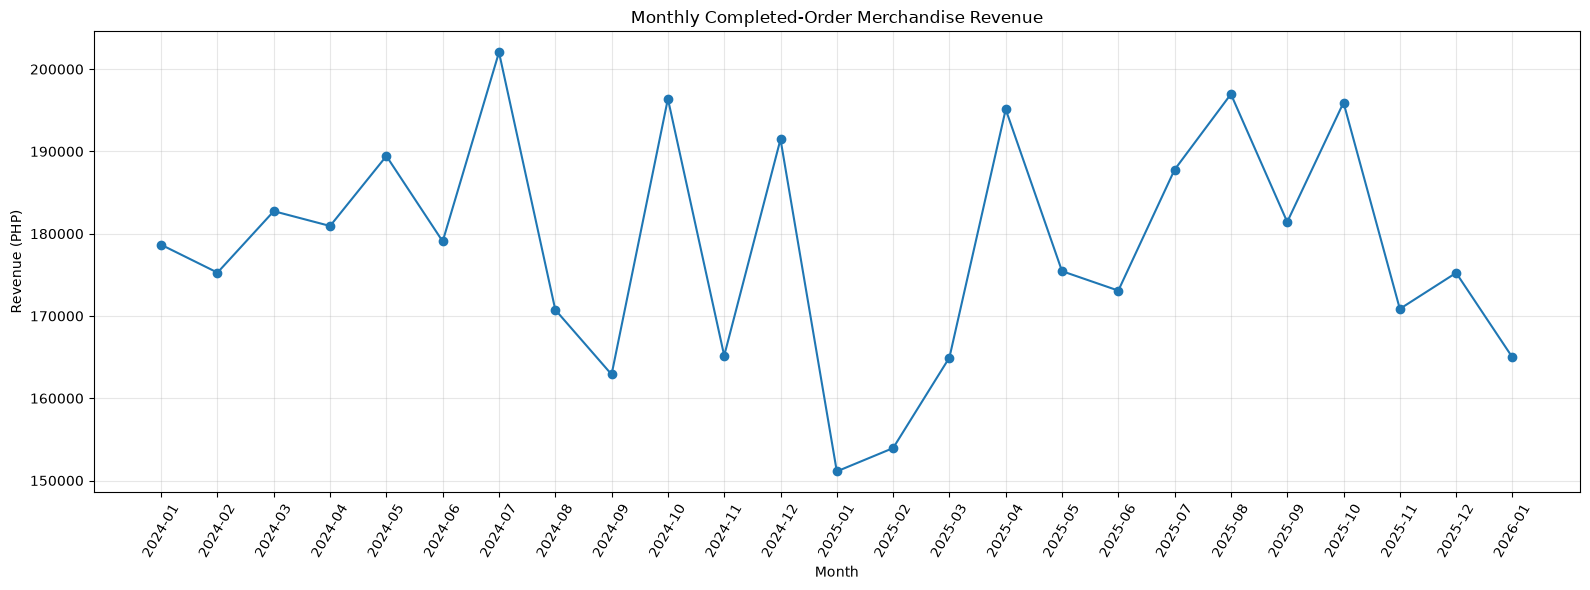

In [95]:
# Visualize monthly revenue trend

import matplotlib.pyplot as plt

monthly_revenue_plot = monthly_revenue.copy()

monthly_revenue_plot.index = (
    monthly_revenue_plot.index.astype(str)
)

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_revenue_plot.index,
    monthly_revenue_plot["total_revenue"],
    marker="o"
)

plt.title("Monthly Completed-Order Merchandise Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (PHP)")

plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [96]:
# Prices were already converted to numeric before the sales fact table was built.
# Reassigning them here would overwrite validated/imputed values.
print("Purchase price dtype:", sales_fact["unit_price_at_purchase"].dtype)
print("Remaining missing prices:", sales_fact["unit_price_at_purchase"].isna().sum())
print("Imputed price records:", sales_fact["price_imputed"].sum())

Purchase price dtype: Float64
Remaining missing prices: 9
Imputed price records: 2227


In [97]:
print(
    sales_fact[
        ["product_id", "product_name", "sales_revenue"]
    ].head(10)
)

  product_id              product_name  sales_revenue
0  PROD00513       HomeEase Sports 313            0.0
1  PROD00124       NovaTech Beauty 892      156.62892
2  PROD00631  BookNest Electronics 252       88.00304
3  PROD00136      GlowCo Groceries 689       94.25283
4  PROD00090         BookNest Home 591      102.30166
5  PROD00022           KidJoy Toys 220      101.96434
6  PROD00112    KidJoy Electronics 871      148.33244
7  PROD00367        NovaTech Books 667      101.08319
8  PROD00294             Acme Home 526      205.53208
9  PROD00523    HomeEase Groceries 198       139.0413


### 3.4.4 Top 10 Products by Revenue

**Business Question:**  
Which 10 products generate the highest merchandise revenue from completed orders?

**Objective:**  
Identify the highest revenue-generating products to understand their contribution to overall sales performance and support product-level business decisions.

**Methodology:**
- Group sales records by product ID and product name.
- Calculate total sales revenue for each product using completed orders only.
- Rank products in descending order of revenue.
- Select the top 10 products for visualization.
- Present the results using a horizontal bar chart.

**Revenue Definition:**  
Sales revenue represents discounted merchandise value from completed orders, excluding shipping fees and refunds.

In [98]:
# Calculate the Top 10 Products by Sales Revenue

top_10_products = (
    sales_fact
    .groupby(["product_id", "product_name"], as_index=False)
    .agg(
        total_revenue=("sales_revenue", "sum")
    )
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
display(top_10_products)

print(
    "\nCombined Top 10 Revenue: ₱",
    f"{top_10_products['total_revenue'].sum():,.2f}"
)

Top 10 Products by Revenue:


,product_id,product_name,total_revenue
607,PROD00608,KidJoy Toys 607,23886.20003
411,PROD00412,GlowCo Fashion 931,20867.74228
136,PROD00137,FreshCart Fashion 562,20740.75098
316,PROD00317,KidJoy Beauty 543,18557.2184
650,PROD00651,FitPro Home 691,18497.98986
757,PROD00758,GlowCo Beauty 566,17938.15452
696,PROD00697,UrbanWear Fashion 229,16698.7751
172,PROD00173,HomeEase Sports 288,15922.34676
451,PROD00452,HomeEase Groceries 174,15872.03039
442,PROD00443,BookNest Groceries 219,15769.61776



Combined Top 10 Revenue: ₱ 184,750.83


In [99]:
# Calculate Top 10 Products' Contribution to Total Revenue

top_10_revenue = top_10_products["total_revenue"].sum()

total_sales_revenue = sales_fact["sales_revenue"].sum()

top_10_contribution = (
    top_10_revenue / total_sales_revenue
) * 100

print(f"Top 10 Products Revenue: ₱{top_10_revenue:,.2f}")

print(f"Total Sales Revenue: ₱{total_sales_revenue:,.2f}")

print(f"Top 10 Revenue Contribution: {top_10_contribution:.2f}%")

Top 10 Products Revenue: ₱184,750.83
Total Sales Revenue: ₱4,461,673.07
Top 10 Revenue Contribution: 4.14%


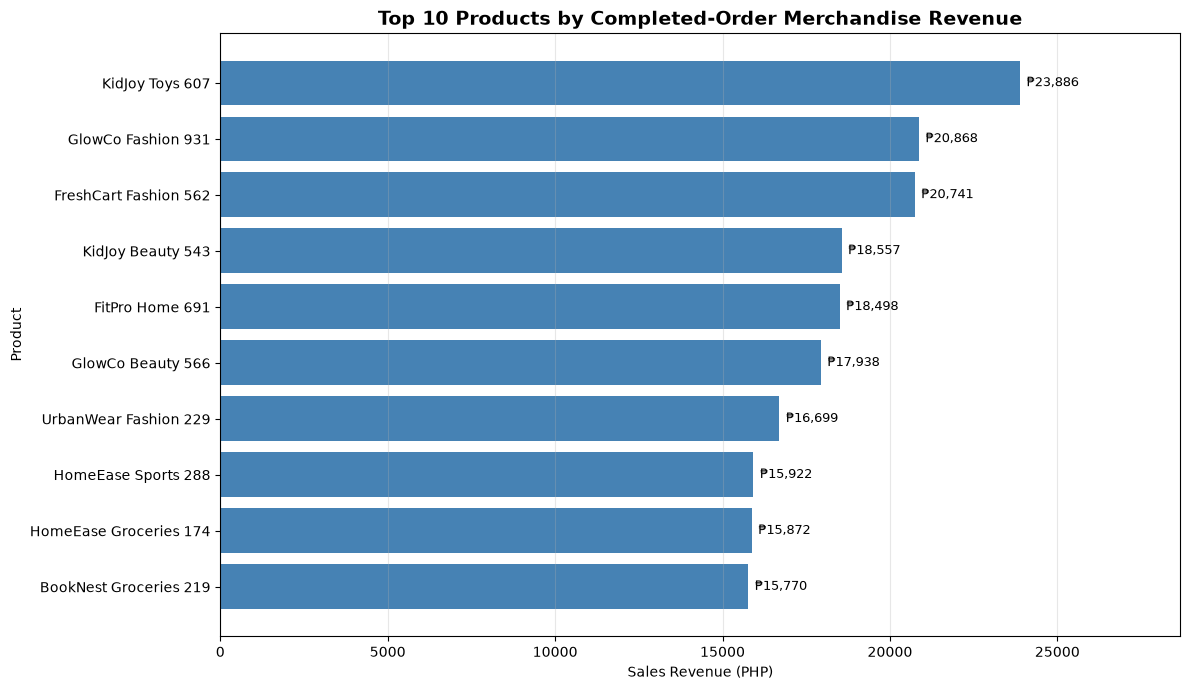

In [100]:
# Visualize Top 10 Products by Revenue

import matplotlib.pyplot as plt

# Reverse ranking so the highest-revenue product appears at the top
top_10_plot = top_10_products.sort_values(
    "total_revenue",
    ascending=True
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_plot["product_name"],
    top_10_plot["total_revenue"],
    color="steelblue"
)

# Add revenue labels
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 200,
        bar.get_y() + bar.get_height() / 2,
        f"₱{width:,.0f}",
        va="center",
        fontsize=9
    )

plt.title(
    "Top 10 Products by Completed-Order Merchandise Revenue",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Sales Revenue (PHP)")
plt.ylabel("Product")

plt.xlim(0, top_10_plot["total_revenue"].max() * 1.20)

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save visualization
plt.savefig(
    "../outputs/figures/top_10_products_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.4.5 Revenue by Region

**Business Question:**  
Which geographic regions contribute the most merchandise revenue from completed orders?

**Objective:**  
Evaluate sales performance across geographic regions to identify leading markets and potential opportunities for further investigation.

**Methodology:**
- Identify the geographic region associated with each customer.
- Aggregate completed-order merchandise revenue by region.
- Rank regions by total sales revenue.
- Visualize regional revenue using a bar chart.

**Revenue Definition:**  
Sales revenue represents discounted merchandise value from completed orders, excluding shipping fees and refunds.

In [101]:
# Identify available geographic columns

geo_columns = [
    col for col in sales_fact.columns
    if any(
        keyword in col.lower()
        for keyword in ["region", "city", "country", "province", "state"]
    )
]

print("Available geographic columns:")
print(geo_columns)

Available geographic columns:
['region_code', 'region_name', 'city']


In [102]:
# Calculate Sales Revenue by Region

regional_revenue = (
    sales_fact
    .groupby("region_name", dropna=False)
    .agg(
        total_revenue=("sales_revenue", "sum"),
        unique_customers=("customer_id", "nunique")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

print("Revenue by Region:")
display(regional_revenue)

print(
    "\nTotal Regional Revenue: ₱",
    f"{regional_revenue['total_revenue'].sum():,.2f}"
)

Revenue by Region:


,region_name,total_revenue,unique_customers
2,Central Luzon,776432.08142,807
3,Central Visayas,756340.56704,808
1,Caraga,740793.62542,774
5,Northern Mindanao,738799.61905,763
4,Metro Manila,736990.26621,809
0,CALABARZON,698016.92865,793
6,NaN,14299.97729,1



Total Regional Revenue: ₱ 4,461,673.07


In [103]:
# Investigate sales records with missing region information

unknown_region = sales_fact[
    sales_fact["region_name"].isna()
]

print("Order item records:", len(unknown_region))

print(
    "Unique customers:",
    unknown_region["customer_id"].nunique()
)

print(
    "Unique orders:",
    unknown_region["order_id"].nunique()
)

print(
    "Completed-order revenue: ₱",
    f"{unknown_region['sales_revenue'].sum():,.2f}"
)

print("\nCustomer IDs:")
print(unknown_region["customer_id"].unique())

Order item records: 111
Unique customers: 1
Unique orders: 43
Completed-order revenue: ₱ 14,299.98

Customer IDs:
<StringArray>
['CUST999999']
Length: 1, dtype: str


In [104]:
# Prepare regional revenue data for visualization

regional_revenue_plot = regional_revenue.copy()

# Label missing geographic information
regional_revenue_plot["region_name"] = (
    regional_revenue_plot["region_name"]
    .fillna("Unknown Region")
)

# Sort regions by revenue
regional_revenue_plot = regional_revenue_plot.sort_values(
    "total_revenue",
    ascending=True
)

# Validate regional revenue totals
print("Regions:", len(regional_revenue_plot))

print(
    "Total Regional Revenue:",
    round(regional_revenue_plot["total_revenue"].sum(), 2)
)

display(regional_revenue_plot)

Regions: 7
Total Regional Revenue: 4461673.07


,region_name,total_revenue,unique_customers
6,Unknown Region,14299.97729,1
0,CALABARZON,698016.92865,793
4,Metro Manila,736990.26621,809
5,Northern Mindanao,738799.61905,763
1,Caraga,740793.62542,774
3,Central Visayas,756340.56704,808
2,Central Luzon,776432.08142,807


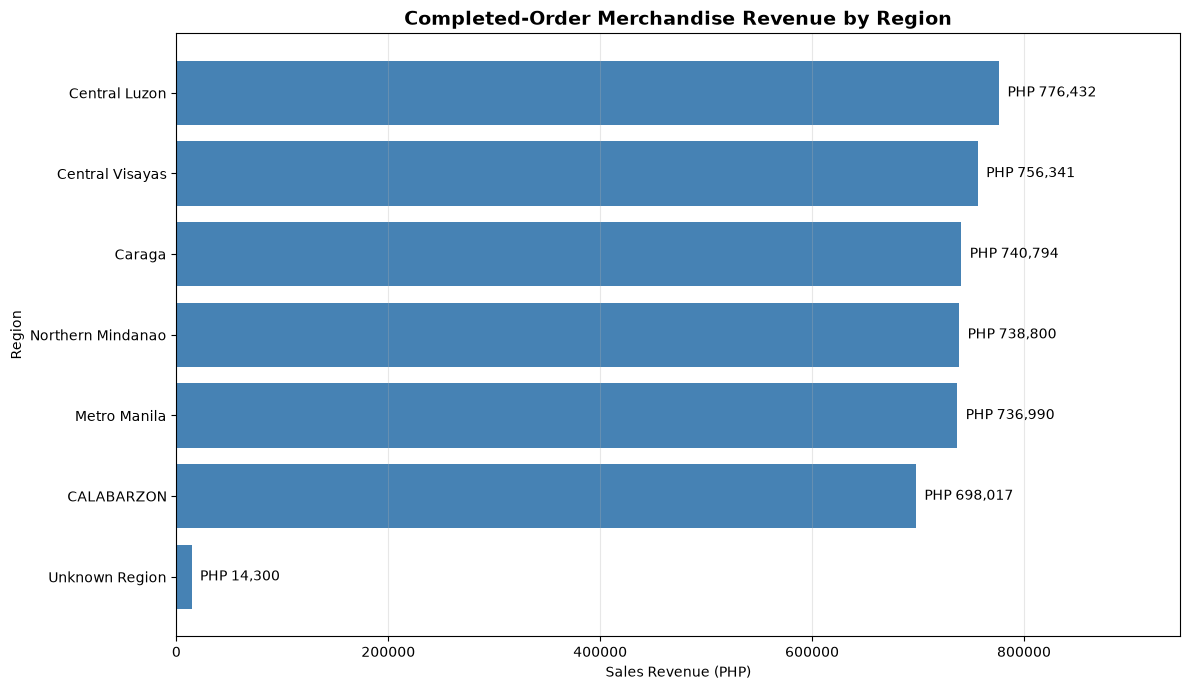

In [105]:
# Visualize Completed-Order Merchandise Revenue by Region

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

bars = plt.barh(
    regional_revenue_plot["region_name"],
    regional_revenue_plot["total_revenue"],
    color="steelblue"
)

# Add revenue labels beside each bar
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 8000,
        bar.get_y() + bar.get_height() / 2,
        f"PHP {width:,.0f}",
        va="center",
        fontsize=10
    )

plt.title(
    "Completed-Order Merchandise Revenue by Region",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Sales Revenue (PHP)")
plt.ylabel("Region")

# Leave space for revenue labels
plt.xlim(
    0,
    regional_revenue_plot["total_revenue"].max() * 1.22
)

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save visualization
plt.savefig(
    "../outputs/figures/regional_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.4.6 Customer Spending Distribution

**Business Question:**  
How is completed-order merchandise revenue distributed across customers?

**Objective:**  
Examine customer spending patterns to understand differences in customer revenue contribution and identify potential customer segments for further analysis.

**Methodology:**
- Aggregate completed-order merchandise revenue by customer ID.
- Calculate total spending for each customer.
- Examine the distribution of customer spending.
- Visualize the distribution using a histogram.

**Revenue Definition:**  
Customer spending represents discounted merchandise revenue from completed orders, excluding shipping fees and refunds.

In [106]:
print("Customer ID column available:",
      "customer_id" in sales_fact.columns)

print("Unique customers:",
      sales_fact["customer_id"].nunique())

print("Customers with completed-order revenue:",
      sales_fact.loc[
          sales_fact["sales_revenue"] > 0,
          "customer_id"
      ].nunique())

Customer ID column available: True
Unique customers: 4755
Customers with completed-order revenue: 4307


In [107]:
# Calculate Total Completed-Order Spending per Customer

customer_spending = (
    sales_fact
    .groupby("customer_id", as_index=False)
    .agg(
        total_spending=("sales_revenue", "sum")
    )
)

# Keep customers with positive completed-order revenue
customer_spending = customer_spending[
    customer_spending["total_spending"] > 0
].copy()

# Calculate descriptive statistics
print("Customers analyzed:", len(customer_spending))

print("\nCustomer Spending Summary:")
display(
    customer_spending["total_spending"].describe().round(2)
)

print(
    "\nTotal Customer Spending: ₱",
    f"{customer_spending['total_spending'].sum():,.2f}"
)

Customers analyzed: 4307

Customer Spending Summary:


count      4307.0
mean      1035.91
std        765.32
min         21.04
25%        461.66
50%        881.91
75%        1448.0
max      14299.98
Name: total_spending, dtype: Float64


Total Customer Spending: ₱ 4,461,673.07


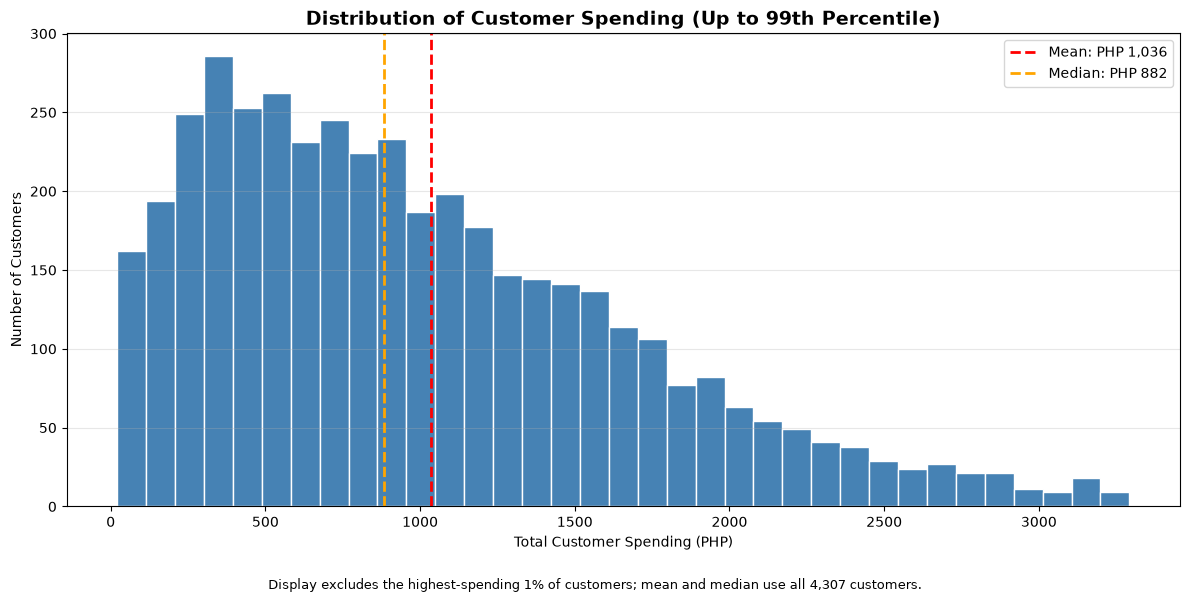

In [108]:
# Visualize Customer Spending Distribution

import matplotlib.pyplot as plt

# Calculate the 99th percentile for visualization
spending_p99 = customer_spending["total_spending"].quantile(0.99)

# Select values within the displayed range
spending_plot = customer_spending.loc[
    customer_spending["total_spending"] <= spending_p99,
    "total_spending"
]

plt.figure(figsize=(12, 6))

plt.hist(
    spending_plot,
    bins=35,
    color="steelblue",
    edgecolor="white"
)

# Add mean and median reference lines (full customer population)
plt.axvline(
    customer_spending["total_spending"].mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label="Mean: PHP 1,036"
)

plt.axvline(
    customer_spending["total_spending"].median(),
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Median: PHP 882"
)

plt.title(
    "Distribution of Customer Spending (Up to 99th Percentile)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Total Customer Spending (PHP)")
plt.ylabel("Number of Customers")

plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.figtext(
    0.5, 0.01,
    "Display excludes the highest-spending 1% of customers; "
    "mean and median use all 4,307 customers.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    "../outputs/figures/customer_spending_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.4.7 Returns and Cancellations Trend

**Business Question:**  
How do order cancellations and returns change over time?

**Objective:**  
Examine monthly cancellation and return patterns to identify potential operational issues and periods requiring further investigation.

**Methodology:**
- Use the orders dataset to identify cancelled and returned orders.
- Aggregate the number of cancelled and returned orders by month.
- Compare monthly trends using a line chart.
- Examine changes in order outcomes over time.

**Metric Definition:**  
Cancellation and return counts are based on distinct orders, not individual order items.

In [109]:
# Inspect order status distribution

print("Order Status Distribution:")

display(
    orders["order_status"].value_counts(dropna=False)
)

print("\nTotal Orders:", orders["order_id"].nunique())

print(
    "\nOrder Date Range:",
    orders["order_datetime"].min(),
    "to",
    orders["order_datetime"].max()
)

Order Status Distribution:


order_status
Completed    9850
Shipped      1808
Pending      1529
Cancelled    1235
Returned      578
Name: count, dtype: int64


Total Orders: 15000

Order Date Range: 2024-01-01 01:17:00 to 2026-01-31 23:36:00


In [110]:
# Calculate Monthly Order Cancellations and Returns

# Create a working copy
order_trends = orders.copy()

# Extract order month
order_trends["order_month"] = (
    order_trends["order_datetime"].dt.to_period("M")
)

# Aggregate order statuses by month
monthly_order_status = (
    order_trends
    .groupby(["order_month", "order_status"])
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

# Reshape statuses into separate columns
monthly_order_status = (
    monthly_order_status
    .pivot(
        index="order_month",
        columns="order_status",
        values="total_orders"
    )
    .fillna(0)
    .astype(int)
)

# Select cancellation and return counts
monthly_issues = monthly_order_status[
    ["Cancelled", "Returned"]
].copy()

print("Months analyzed:", len(monthly_issues))

print(
    "Total Cancelled Orders:",
    monthly_issues["Cancelled"].sum()
)

print(
    "Total Returned Orders:",
    monthly_issues["Returned"].sum()
)

print("\nFirst five months:")
display(monthly_issues.head())

Months analyzed: 25
Total Cancelled Orders: 1235
Total Returned Orders: 578

First five months:


order_status,Cancelled,Returned
order_month,,
2024-01,43,20
2024-02,43,17
2024-03,48,31
2024-04,55,17
2024-05,48,27


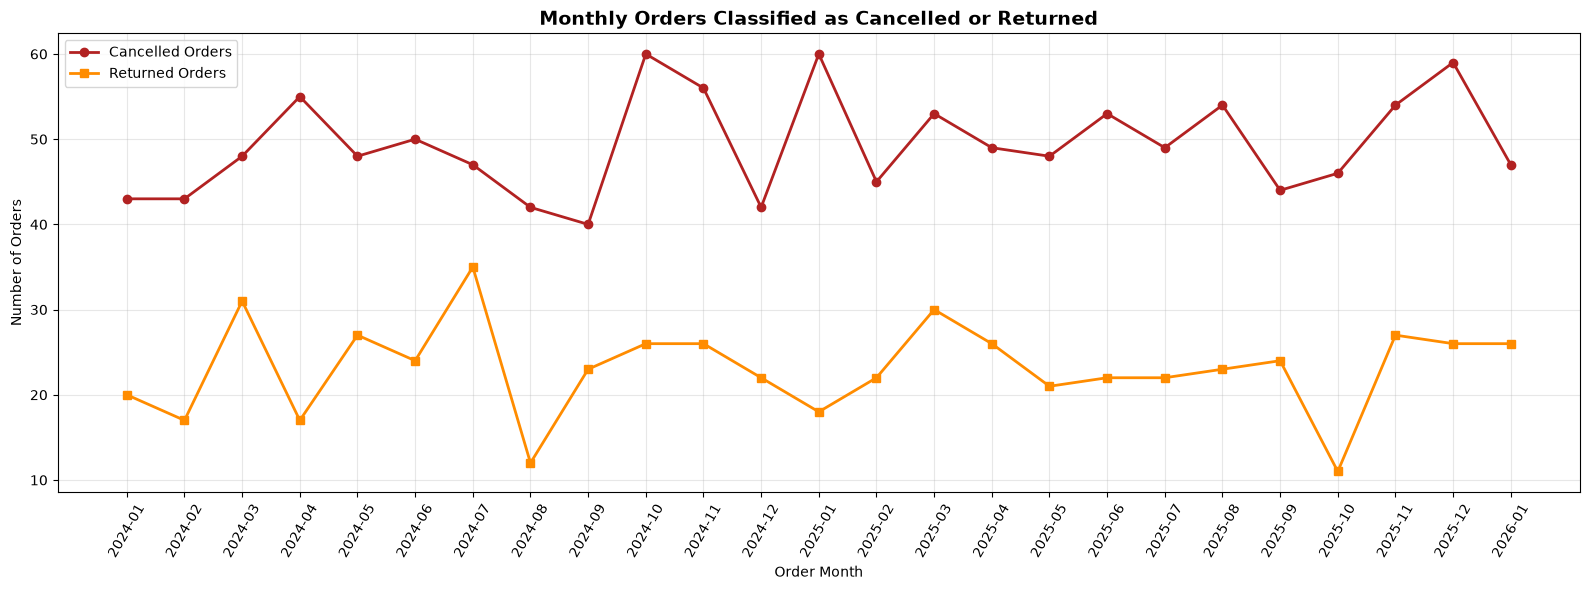

In [111]:
# Visualize Monthly Cancelled and Returned Orders

import matplotlib.pyplot as plt

# Prepare monthly data for visualization
monthly_issues_plot = monthly_issues.copy()

monthly_issues_plot.index = (
    monthly_issues_plot.index.astype(str)
)

plt.figure(figsize=(16, 6))

# Plot cancelled orders
plt.plot(
    monthly_issues_plot.index,
    monthly_issues_plot["Cancelled"],
    marker="o",
    linewidth=2,
    color="firebrick",
    label="Cancelled Orders"
)

# Plot returned orders
plt.plot(
    monthly_issues_plot.index,
    monthly_issues_plot["Returned"],
    marker="s",
    linewidth=2,
    color="darkorange",
    label="Returned Orders"
)

plt.title(
    "Monthly Orders Classified as Cancelled or Returned",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Order Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=60)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

# Save visualization
plt.savefig(
    "../outputs/figures/monthly_cancellations_returns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [112]:
# Calculate Monthly Cancellation and Return Rates

monthly_order_rates = monthly_order_status.copy()

# Calculate total orders per month
monthly_order_rates["total_orders"] = (
    monthly_order_rates.sum(axis=1)
)

# Calculate cancellation rate
monthly_order_rates["cancellation_rate"] = (
    monthly_order_rates["Cancelled"]
    / monthly_order_rates["total_orders"]
) * 100

# Calculate return rate
monthly_order_rates["return_rate"] = (
    monthly_order_rates["Returned"]
    / monthly_order_rates["total_orders"]
) * 100

# Display results
display(
    monthly_order_rates[
        [
            "total_orders",
            "Cancelled",
            "Returned",
            "cancellation_rate",
            "return_rate"
        ]
    ].round(2)
)

print(
    "\nOverall Cancellation Rate:",
    f"{orders['order_status'].eq('Cancelled').mean() * 100:.2f}%"
)

print(
    "Overall Return Rate:",
    f"{orders['order_status'].eq('Returned').mean() * 100:.2f}%"
)

order_status,total_orders,Cancelled,Returned,cancellation_rate,return_rate
order_month,,,,,
2024-01,603,43,20,7.13,3.32
2024-02,544,43,17,7.90,3.12
2024-03,626,48,31,7.67,4.95
2024-04,602,55,17,9.14,2.82
2024-05,613,48,27,7.83,4.40
2024-06,630,50,24,7.94,3.81
2024-07,645,47,35,7.29,5.43
2024-08,603,42,12,6.97,1.99
2024-09,576,40,23,6.94,3.99



Overall Cancellation Rate: 8.23%
Overall Return Rate: 3.85%


### 3.4.8 Revenue by Product Category

**Business question:** Which product categories contribute the most completed-order merchandise revenue?

This analysis uses the validated `sales_revenue` measure and retains missing product categories as **Unknown Category**, so the category totals reconcile to overall revenue. Units sold are counted only for revenue-eligible order-item rows.

In [113]:
# Revenue by product category — completed-order merchandise revenue
category_analysis = sales_fact.copy()
category_analysis["category_reporting"] = category_analysis["category"].fillna("Unknown Category")
category_revenue = (
    category_analysis.groupby("category_reporting", dropna=False)
    .agg(total_revenue=("sales_revenue", "sum"))
    .reset_index().rename(columns={"category_reporting": "category"})
)
category_units = (
    category_analysis.loc[category_analysis["revenue_eligible"]]
    .groupby("category_reporting")["quantity"].sum()
)
category_revenue["units_sold"] = (
    category_revenue["category"].map(category_units).fillna(0).astype(int)
)
category_revenue["revenue_share_pct"] = (
    category_revenue["total_revenue"] / sales_fact["sales_revenue"].sum() * 100
)
category_revenue = category_revenue.sort_values("total_revenue", ascending=False).reset_index(drop=True)
display(category_revenue.round(2))
assert abs(category_revenue["total_revenue"].sum() - total_revenue) < 0.01
assert category_revenue["units_sold"].sum() == total_units_sold
print("PASS | Category revenue and eligible units reconcile with overall KPIs.")

,category,total_revenue,units_sold,revenue_share_pct
0,Toys,610562.72,6670,13.68
1,Electronics,605362.95,7498,13.57
2,Fashion,580005.88,6421,13.0
3,Home & Kitchen,568780.36,6410,12.75
4,Beauty,566388.58,6842,12.69
5,Groceries,519356.21,5879,11.64
6,Books,516483.02,6876,11.58
7,Sports,480057.38,5254,10.76
8,Unknown Category,14675.96,161,0.33


PASS | Category revenue and eligible units reconcile with overall KPIs.


**Interpretation:** Toys and Electronics lead category revenue, but the eight identified categories each contribute a relatively similar share. Transactions with missing product categories are retained under **Unknown Category**. Revenue alone does not establish category profitability.

### 3.4.9 New vs. Repeat Customers

**Business question:** How much of the observed order activity comes from first recorded orders versus subsequent orders?

**Definition:** For each `customer_id`, the earliest recorded order in the available dataset is classified as **New**; subsequent orders are **Repeat**. Orders are sequenced by `order_datetime`, with `order_id` as a deterministic tie-breaker. This is a **within-dataset order classification**, not proof of a customer's first-ever purchase. The primary comparison uses all recorded orders, with a separate completed-order view for revenue. Customers with invalid reference IDs remain in the analysis and are flagged as a data-quality limitation.

In [114]:
# Classify unique orders at the order grain, never at the order-item grain
customer_orders = (
    orders[["order_id", "customer_id", "order_datetime", "order_status"]]
    .drop_duplicates(subset=["order_id"])
    .sort_values(["customer_id", "order_datetime", "order_id"])
    .copy()
)
assert len(customer_orders) == orders["order_id"].nunique(), "Unexpected duplicate order IDs."
assert customer_orders["customer_id"].notna().all(), "Missing customer IDs need review."
customer_orders["customer_order_number"] = customer_orders.groupby("customer_id").cumcount() + 1
customer_orders["customer_type"] = customer_orders["customer_order_number"].eq(1).map({True: "New", False: "Repeat"})
customer_type_summary = (
    customer_orders.groupby("customer_type")["order_id"]
    .nunique().reindex(["New", "Repeat"], fill_value=0)
    .rename("orders").to_frame()
)
customer_type_summary["order_share_pct"] = customer_type_summary["orders"] / len(customer_orders) * 100
print("ALL RECORDED ORDERS — FIRST VS. SUBSEQUENT ORDER")
display(customer_type_summary.round(2))
print("Unique customer IDs:", customer_orders["customer_id"].nunique())
assert customer_type_summary["orders"].sum() == len(orders)

# Completed-order revenue by customer order classification
completed_order_revenue = (
    sales_fact.loc[sales_fact["order_status"].eq("Completed")]
    .groupby("order_id")["sales_revenue"].sum()
)
customer_orders["completed_order_revenue"] = (
    customer_orders["order_id"].map(completed_order_revenue).fillna(0)
)
completed_type_summary = (
    customer_orders.loc[customer_orders["order_status"].eq("Completed")]
    .groupby("customer_type")
    .agg(completed_orders=("order_id", "nunique"), revenue=("completed_order_revenue", "sum"))
    .reindex(["New", "Repeat"], fill_value=0)
)
completed_type_summary["revenue_share_pct"] = completed_type_summary["revenue"] / total_revenue * 100
print("\nCOMPLETED ORDERS — CLASSIFIED BY FIRST/SUBSEQUENT RECORDED ORDER")
display(completed_type_summary.round(2))
assert completed_type_summary["completed_orders"].sum() == total_completed_orders
assert abs(completed_type_summary["revenue"].sum() - total_revenue) < 0.01
print("PASS | New/repeat order counts and completed-order revenue reconcile.")

ALL RECORDED ORDERS — FIRST VS. SUBSEQUENT ORDER


,orders,order_share_pct
customer_type,,
New,4755,31.7
Repeat,10245,68.3


Unique customer IDs: 4755

COMPLETED ORDERS — CLASSIFIED BY FIRST/SUBSEQUENT RECORDED ORDER


,completed_orders,revenue,revenue_share_pct
customer_type,,,
New,3124,1420581.91,31.84
Repeat,6726,3041091.16,68.16


PASS | New/repeat order counts and completed-order revenue reconcile.


**Interpretation guidance:** The **New** and **Repeat** groups describe orders, not mutually exclusive customer populations. A customer may contribute one New order and several Repeat orders. Because classification uses the first order *observed in the dataset*, it is subject to left-censoring and should not be presented as a lifetime acquisition or retention metric. A customer's first *completed* order may be classified Repeat if they previously placed an order with another status.

## 3.5 Key Findings and Business Insights

This section consolidates the results of the retail sales analysis, highlighting important patterns in revenue performance, product contributions, geographic distribution, customer spending, and order outcomes.

Each finding is supported by quantitative evidence and interpreted in the context of potential business implications.

The analysis focuses on completed-order merchandise revenue, calculated after order-level discounts and excluding shipping fees and refunds. Cancellation and return metrics are evaluated separately using order-level records.

### 3.5.1 Overall Sales Performance

The dataset contains 15,000 orders recorded between January 2024 and January 2026, of which 9,850 are classified as Completed.

Completed orders generated **PHP 4,461,673.07 in discounted merchandise revenue**, representing the primary revenue measure used throughout the analysis.

Approximately **65.67% of all orders** are classified as Completed. The remaining orders are classified as Shipped, Pending, Cancelled, or Returned.

**Business Implication:**

Order completion is an important indicator of sales performance. Monitoring the proportion of orders reaching Completed status can help the business evaluate order processing outcomes and identify opportunities for operational investigation.

However, orders classified as Pending or Shipped should not automatically be considered unsuccessful, as they may still be progressing through the fulfillment process.

### 3.5.2 Monthly Revenue Trends

Completed-order merchandise revenue totaled **PHP 2,174,844.01 in 2024** and **PHP 2,121,862.45 in 2025**, representing a year-over-year decrease of approximately **2.44%**.

The number of completed orders also declined from **4,817 in 2024 to 4,661 in 2025**, indicating that reduced order volume may have contributed to the decrease in revenue.

Monthly revenue fluctuated throughout the analysis period without demonstrating a consistent upward or downward trend.

January 2026 generated **PHP 164,966.62** in completed-order merchandise revenue. However, because only one month of 2026 is available, this figure should not be directly compared with full-year totals.

**Business Implication:**

The modest year-over-year revenue decline suggests an opportunity to investigate changes in completed-order volume and average order value.

Monitoring these metrics together would help management determine whether future revenue fluctuations are primarily driven by transaction volume, customer spending, or both.

### 3.5.3 Product Revenue Concentration

The ten highest-revenue products collectively generated **PHP 184,750.83**, representing approximately **4.14% of total completed-order merchandise revenue**.

The highest-performing product, **KidJoy Toys 607 (PROD00608)**, contributed **PHP 23,886.20**, followed by GlowCo Fashion 931 and FreshCart Fashion 562.

The relatively small combined contribution of the top ten products suggests that revenue is distributed across a broad product portfolio rather than being heavily concentrated among a few leading products.

However, this finding does not establish that all products contribute equally or that the entire portfolio is equally profitable.

**Business Implication:**

Management should evaluate product performance across the broader catalog rather than relying exclusively on the highest-revenue products.

Combining revenue analysis with product profitability, sales volume, and inventory availability would provide a stronger basis for decisions involving stock allocation, promotions, and product assortment.

### 3.5.4 Geographic Sales Performance

**Central Luzon** generated the highest completed-order merchandise revenue at **PHP 776,432.08**, representing approximately **17.40% of total sales revenue**.

Central Visayas followed with PHP 756,340.57, while CALABARZON recorded the lowest revenue among the six identified regions at PHP 698,016.93.

The difference between the highest- and lowest-revenue identified regions was approximately PHP 78,415, suggesting that revenue is relatively balanced across the geographic markets represented in the dataset.

An additional **PHP 14,299.98 (0.32% of total revenue)** could not be attributed to a known region. Further investigation traced these transactions to customer ID `CUST999999`, which was associated with 43 orders and 111 order-item records.

These transactions were retained in the analysis and classified as **Unknown Region** to preserve revenue reconciliation and maintain transparency regarding missing geographic information.

**Business Implication:**

Regional revenue comparisons can help management identify markets for further investigation. However, revenue alone does not establish regional market potential or customer demand.

Additional analysis of customer counts, order frequency, and average spending would help determine whether regional differences reflect customer-base size or purchasing behavior.

The unidentified customer-region records also highlight an opportunity to improve customer data validation and geographic reporting accuracy.

### 3.5.5 Customer Spending Patterns

The analysis identified **4,307 customers with positive completed-order merchandise revenue**, generating a combined **PHP 4,461,673.07** during the study period.

Average spending per revenue-contributing customer was **PHP 1,035.91**, while median spending was **PHP 881.91**.

The middle 50% of customers spent between approximately **PHP 461.66 and PHP 1,448.00**, indicating variation in individual customer revenue contributions.

The spending distribution was positively skewed, with a smaller number of customers contributing substantially higher revenue than the typical customer.

The highest observed customer spending was **PHP 14,299.98**, associated with the previously identified customer record lacking geographic information.

For visualization purposes, the histogram was restricted to spending values at or below the 99th percentile to improve readability. However, all 4,307 revenue-contributing customers were retained in the descriptive statistics and overall revenue calculations.

**Business Implication:**

Differences in customer spending suggest opportunities for further customer segmentation.

Management could examine purchase frequency, average order value, and product preferences to identify meaningful customer groups and develop more targeted marketing strategies.

However, spending alone should not be interpreted as customer loyalty or profitability without additional supporting analysis.

### 3.5.6 Order Cancellations and Returns

Of the **15,000 orders** analyzed, **1,235 were classified as Cancelled (8.23%)**, while **578 were classified as Returned (3.85%)**.

Together, these categories represented approximately **12.09% of all orders**, indicating that cancellations and returns are important operational outcomes to monitor.

Monthly cancellation rates fluctuated throughout the analysis period, reaching a maximum of **10.77% in January 2025**, when 60 of 557 orders were classified as Cancelled.

Return rates were consistently lower than cancellation rates, reaching their highest monthly level of **5.43% in July 2024**, when 35 of 645 orders were classified as Returned.

Although both metrics fluctuated, the analysis did not establish a consistent upward or downward trend.

Monthly rates were calculated using each order's original order month and its recorded status. Consequently, these figures describe the proportion of orders from each month classified as Cancelled or Returned, rather than the timing of the cancellation or return events themselves.

**Business Implication:**

Cancellations and returns represent opportunities for further operational investigation.

Management should examine cancellation reasons, return reasons, product categories, inventory availability, and fulfillment performance to identify potential contributing factors.

Tracking cancellation and return rates alongside total order volume would provide a more meaningful basis for evaluating operational performance over time.

However, the current analysis does not establish the underlying causes of these outcomes, so specific corrective actions should be based on additional investigation.

## 3.6 Business Recommendations

Based on the findings of the retail sales analysis, the following recommendations aim to support data-driven decision-making and identify opportunities for improving sales performance and operational efficiency.

### Recommendation 1: Establish a Monthly Sales Performance Monitoring Framework

**Supporting Evidence:**

Completed-order merchandise revenue decreased by approximately **2.44% between 2024 and 2025**, accompanied by a decline in completed orders from 4,817 to 4,661.

**Recommended Action:**

Implement a monthly sales performance report or dashboard that tracks:

- Completed-order merchandise revenue
- Number of completed orders
- Average order value (AOV)
- Month-over-month and year-over-year revenue changes
- Revenue performance by product and region

Management should review these indicators regularly to identify changes in transaction volume and customer spending.

**Expected Business Value:**

This framework would provide greater visibility into sales performance and help management distinguish between revenue changes driven by order volume and those associated with average transaction value.

**Suggested Success Measures:**

- Monthly revenue growth rate
- Completed-order growth rate
- Average order value
- Percentage of reporting periods reviewed

### Recommendation 2: Investigate and Monitor Order Cancellations and Returns

**Supporting Evidence:**

Of the 15,000 orders analyzed, **8.23% were classified as Cancelled**, while **3.85% were classified as Returned**.

Cancellation rates reached **10.77% in January 2025**, while return rates peaked at **5.43% in July 2024**.

**Recommended Action:**

Introduce a structured process for recording and analyzing cancellation and return reasons.

Where reliable data is available, examine these outcomes by:

- Product and product category
- Customer region
- Order value
- Shipping and fulfillment performance
- Documented cancellation or return reason

Management should monitor monthly cancellation and return rates alongside order volumes to identify recurring patterns and prioritize further investigation.

**Expected Business Value:**

Understanding the factors associated with cancellations and returns could help the business identify preventable operational issues and develop more targeted improvement initiatives.

**Suggested Success Measures:**

- Monthly cancellation rate
- Monthly return rate
- Percentage of cancellations with documented reasons
- Percentage of returns with documented reasons
- Changes in cancellation and return rates following improvement initiatives

**Implementation Consideration:**

These recommendations should initially focus on establishing reliable monitoring and identifying contributing factors. Specific interventions should be selected only after further analysis confirms the issues they are intended to address.

## 3.7 Conclusion

This project analyzed a synthetic Philippine retail sales dataset covering **15,000 orders from January 2024 to January 2026**, using Python for data cleaning, validation, transformation, exploratory analysis, and visualization.

The analysis identified **PHP 4,461,673.07 in completed-order merchandise revenue** across 9,850 completed orders.

Key findings included a **2.44% year-over-year revenue decline from 2024 to 2025**, relatively diversified product revenue contributions, differences in geographic sales performance, and a positively skewed customer spending distribution.

Additionally, **8.23% of orders were classified as Cancelled**, while **3.85% were classified as Returned**, highlighting opportunities for further operational investigation.

Based on these findings, the project recommended establishing a monthly sales performance monitoring framework and improving the collection and analysis of cancellation and return information.

### Analytical Limitations

Several limitations should be considered when interpreting the results:

- The dataset is synthetic, so findings should not be interpreted as evidence of actual Philippine retail market conditions.
- Revenue calculations include discounted merchandise revenue from completed orders but exclude shipping fees and refunds.
- Missing values and invalid reference records required documented handling during data preparation.
- Customer spending represents revenue contribution during the available study period rather than customer lifetime value.
- Cancellation and return metrics describe recorded order statuses rather than the exact timing or causes of these events.
- Product profitability and the underlying causes of operational outcomes could not be established from the available analysis.

### Final Assessment

The project demonstrates how a structured data analytics workflow can transform raw transactional records into validated performance indicators, visualizations, and actionable business recommendations.

By combining data-quality checks, reproducible calculations, descriptive analysis, and business interpretation, the analysis provides a foundation for more informed retail performance monitoring and future investigation.

## 4. Final Reproducibility and Output Validation

The following checks verify key reconciliations and saved chart files after running all notebook cells.

In [115]:
from pathlib import Path

expected = {
    "Order count": (len(orders), 15000),
    "Completed orders": (int(orders["order_status"].eq("Completed").sum()), 9850),
    "Revenue-eligible rows": (int(sales_fact["revenue_eligible"].sum()), 24404),
    "Cancelled orders": (int(orders["order_status"].eq("Cancelled").sum()), 1235),
    "Returned orders": (int(orders["order_status"].eq("Returned").sum()), 578),
}
results = {}
for label, (actual, target) in expected.items():
    results[label] = actual == target
    print(f'{"PASS" if results[label] else "FAIL"} | {label}: {actual:,} (expected {target:,})')

actual_revenue = float(sales_fact["sales_revenue"].sum())
results["Revenue reconciliation"] = abs(actual_revenue - 4461673.07) < 0.01
print(f'{"PASS" if results["Revenue reconciliation"] else "FAIL"} | Revenue: PHP {actual_revenue:,.2f}')

figures = [
    "monthly_revenue_trend.png", "top_10_products_revenue.png",
    "regional_revenue.png", "customer_spending_distribution.png",
    "monthly_cancellations_returns.png",
]
for name in figures:
    file = Path("../outputs/figures") / name
    results[f"Chart {name}"] = file.is_file() and file.stat().st_size > 0
    print(f'{"PASS" if results[f"Chart {name}"] else "FAIL"} | {name}')

# Additional rubric KPI checks
results["Category revenue"] = abs(category_revenue["total_revenue"].sum() - total_revenue) < 0.01
results["Category units"] = int(category_revenue["units_sold"].sum()) == int(total_units_sold)
results["New/repeat order counts"] = int(customer_type_summary["orders"].sum()) == len(orders)
results["New/repeat completed revenue"] = abs(completed_type_summary["revenue"].sum() - total_revenue) < 0.01
for label in ["Category revenue", "Category units", "New/repeat order counts", "New/repeat completed revenue"]:
    print(f'{"PASS" if results[label] else "FAIL"} | {label}')
print("\n" + ("ALL CHECKS PASSED" if all(results.values()) else "SOME CHECKS FAILED"))


PASS | Order count: 15,000 (expected 15,000)
PASS | Completed orders: 9,850 (expected 9,850)
PASS | Revenue-eligible rows: 24,404 (expected 24,404)
PASS | Cancelled orders: 1,235 (expected 1,235)
PASS | Returned orders: 578 (expected 578)
PASS | Revenue: PHP 4,461,673.07
PASS | monthly_revenue_trend.png
PASS | top_10_products_revenue.png
PASS | regional_revenue.png
PASS | customer_spending_distribution.png
PASS | monthly_cancellations_returns.png
PASS | Category revenue
PASS | Category units
PASS | New/repeat order counts
PASS | New/repeat completed revenue

ALL CHECKS PASSED
